



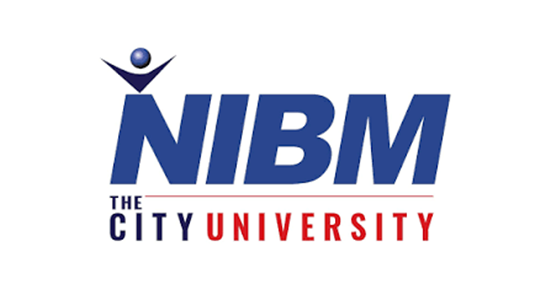




# **ARTIFICIAL NEURAL NETWORK ASSIGNMENT**



*   ATHAPATHTHU WIJEKOON MUDIYANSELAGE CHALIDU MINARA BANDARA WIJEKOON
*   KIC-BSCCSAI-251P-002
*   Kandy Innovation Centre

*   10/11/2026

# Human Activity Recognition Using Smartphone Sensors

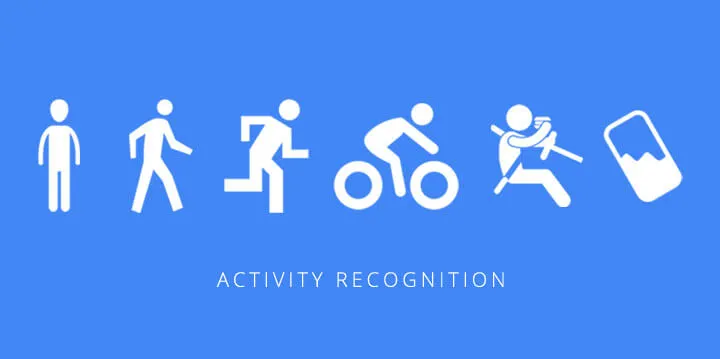

## 1. Importing Libraries

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
import json
import joblib


In [2]:
# %pip install --upgrade "keras==3.15.1"

In [3]:
import keras
print(keras.__version__)

3.15.1


## 2. Dataset Acquisition and Loading


In [4]:
from urllib.request import urlretrieve
from zipfile import ZipFile
from io import BytesIO


In [5]:
# 1. Create a folder for our dataset
data_fol = Path("data")
data_fol.mkdir(exist_ok=True)

# 2. Official UCI HAR download link
url = ("https://archive.ics.uci.edu/static/public/240/"
    "human%2Bactivity%2Brecognition%2Busing%2Bsmartphones.zip")

# 3. Download the data
zip_path = data_fol / "uci_har_download.zip"

if not zip_path.exists():
    print("Downloading UCI HAR dataset...")
    urlretrieve(url, zip_path)

print("Download completed!")

# Extract the downloaded dataset
if not (data_fol / "UCI HAR Dataset/train/X_train.txt").exists():
    with ZipFile(zip_path) as archive:
        with ZipFile(BytesIO(archive.read("UCI HAR Dataset.zip"))) as dataset_zip:
            members = [name for name in dataset_zip.namelist()
                       if name.startswith("UCI HAR Dataset/")]
            dataset_zip.extractall(data_fol, members=members)
    print("Dataset extracted.")


Download completed!


In [6]:
dataset = Path("data/UCI HAR Dataset")
dataset_path = dataset

# Load training data
X_train = pd.read_csv(dataset / "train/X_train.txt", sep=r"\s+", header=None)
y_train = pd.read_csv(dataset / "train/y_train.txt", header=None)

In [7]:
# Load testing data
X_test = pd.read_csv( dataset / "test/X_test.txt", sep=r"\s+", header=None)
y_test = pd.read_csv(dataset / "test/y_test.txt",header=None)

In [8]:
# dataset information
print("Training data shape:", X_train.shape)
print("Training labels shape:", y_train.shape)
print("Testing data shape:", X_test.shape)
print("Testing labels shape:", y_test.shape)

Training data shape: (7352, 561)
Training labels shape: (7352, 1)
Testing data shape: (2947, 561)
Testing labels shape: (2947, 1)


In [9]:
X_train.head()

,0,1,2,3,4,5,6,7,8,9,...,551,552,553,554,555,556,557,558,559,560
0,0.288585,-0.020294,-0.132905,-0.995279,-0.983111,-0.913526,-0.995112,-0.983185,-0.923527,-0.934724,...,-0.074323,-0.298676,-0.710304,-0.112754,0.030400,-0.464761,-0.018446,-0.841247,0.179941,-0.058627
1,0.278419,-0.016411,-0.123520,-0.998245,-0.975300,-0.960322,-0.998807,-0.974914,-0.957686,-0.943068,...,0.158075,-0.595051,-0.861499,0.053477,-0.007435,-0.732626,0.703511,-0.844788,0.180289,-0.054317
2,0.279653,-0.019467,-0.113462,-0.995380,-0.967187,-0.978944,-0.996520,-0.963668,-0.977469,-0.938692,...,0.414503,-0.390748,-0.760104,-0.118559,0.177899,0.100699,0.808529,-0.848933,0.180637,-0.049118
3,0.279174,-0.026201,-0.123283,-0.996091,-0.983403,-0.990675,-0.997099,-0.982750,-0.989302,-0.938692,...,0.404573,-0.117290,-0.482845,-0.036788,-0.012892,0.640011,-0.485366,-0.848649,0.181935,-0.047663
4,0.276629,-0.016570,-0.115362,-0.998139,-0.980817,-0.990482,-0.998321,-0.979672,-0.990441,-0.942469,...,0.087753,-0.351471,-0.699205,0.123320,0.122542,0.693578,-0.615971,-0.847865,0.185151,-0.043892


In [10]:
# Load activity names
activity_labels = pd.read_csv( dataset / "activity_labels.txt", sep=r"\s+", header=None, names=["Activity_ID", "Activity_Name"])

In [11]:
# Display all activity
print("The six human activities:")
display(activity_labels)

The six human activities:


,Activity_ID,Activity_Name
0,1,WALKING
1,2,WALKING_UPSTAIRS
2,3,WALKING_DOWNSTAIRS
3,4,SITTING
4,5,STANDING
5,6,LAYING


## 3. Data Exploration and Quality Checks

### 3.1 Activity Distribution


In [12]:
# Create a folder to save graphs
Path("figures").mkdir(exist_ok=True)

# Match activity numbers to their names
activity_map = dict(zip( activity_labels["Activity_ID"], activity_labels["Activity_Name"]))

# Count training samples
activity_counts = ( y_train[0]
    .map(activity_map)
    .value_counts()
    .reindex(activity_labels["Activity_Name"]))

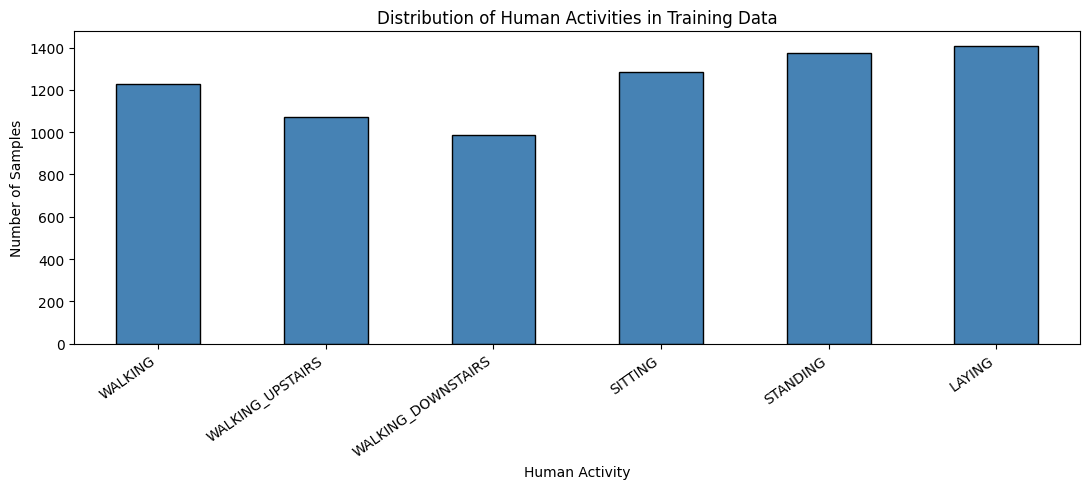

In [13]:
# Create bar chart
plt.figure(figsize=(11, 5))
activity_counts.plot(kind="bar",color="steelblue", edgecolor="black")
plt.xlabel("Human Activity")
plt.ylabel("Number of Samples")
plt.xticks(rotation=35, ha="right")
plt.title("Distribution of Human Activities in Training Data")
plt.tight_layout()
# Saving graph
plt.savefig("figures/activity_distribution.png", dpi=300)
plt.show()

In [14]:
print(activity_counts)

Activity_Name
WALKING               1226
WALKING_UPSTAIRS      1073
WALKING_DOWNSTAIRS     986
SITTING               1286
STANDING              1374
LAYING                1407
Name: count, dtype: int64


### 3.2 Data Quality Checks: Missing Values and Duplicates


In [15]:
print("Total training samples:", len(X_train))
print("Missing values:", X_train.isnull().sum().sum())
print("Duplicate feature rows:", X_train.duplicated().sum())
print("Number of features:",X_train.shape[1])

Total training samples: 7352
Missing values: 0
Duplicate feature rows: 0
Number of features: 561


### 3.3 Sensor Feature Distributions


In [16]:
# Read the names of all 561 features
features = pd.read_csv(dataset / "features.txt",sep=r"\s+",header=None,names=["Feature_ID", "Feature_Name"])

# Select one accelerometer-derived feature
selected_feature = "tBodyAcc-std()-X"

# Find the correct column number
feature_index = int( features.loc[features["Feature_Name"] == selected_feature,"Feature_ID"].iloc[0]) - 1

# Create a dataset for plotting
sensor_df = pd.DataFrame({"Activity": y_train[0].map(activity_map),"Acceleration_Variability": X_train.iloc[:, feature_index]})

# Define activity order
activity_order = activity_labels["Activity_Name"].tolist()

# Prepare data for each activity

In [17]:
plot_data = [sensor_df.loc[sensor_df["Activity"] == activity,"Acceleration_Variability"]
    for activity in activity_order]

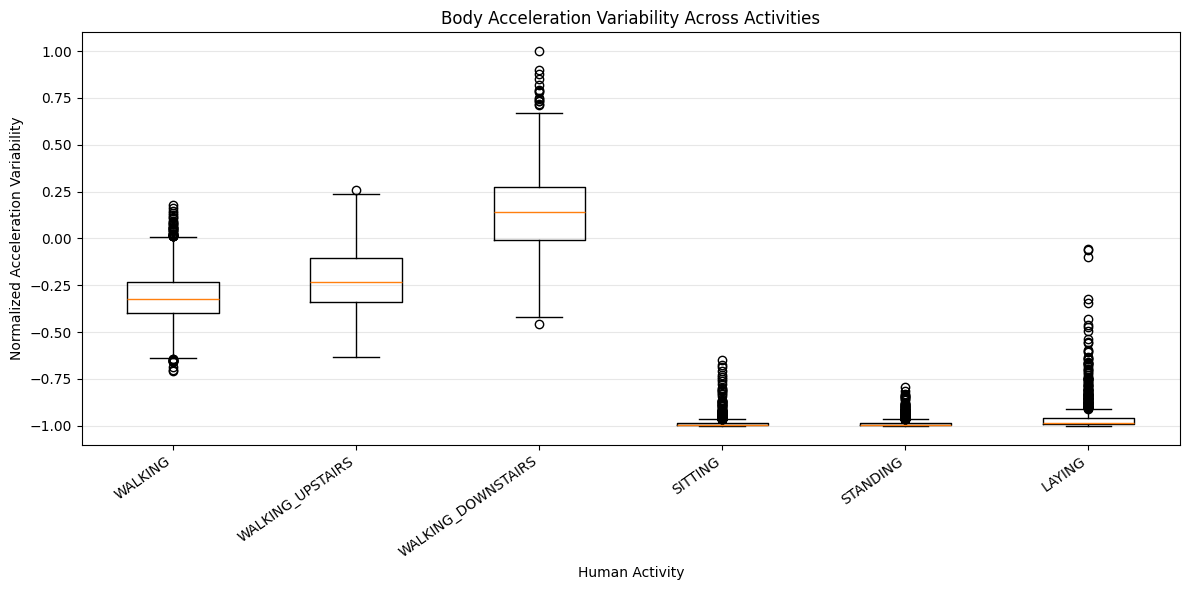

In [18]:
# Create box plot
plt.figure(figsize=(12, 6))

plt.boxplot( plot_data,tick_labels=activity_order)
plt.xlabel("Human Activity")
plt.ylabel("Normalized Acceleration Variability")
plt.title("Body Acceleration Variability Across Activities")
plt.xticks(rotation=35, ha="right")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

In [19]:
plt.savefig("figures/sensor_activity_boxplot.png", dpi=300)

<Figure size 640x480 with 0 Axes>

## 4. Participant Splitting and Leakage Checks


In [20]:
# Load participant IDs 
subject_train = pd.read_csv( dataset / "train/subject_train.txt",header=None)[0].to_numpy()
subject_test = pd.read_csv( dataset / "test/subject_test.txt", header=None)[0].to_numpy()


In [21]:
print("Training participants:", len(np.unique(subject_train)))
print("Testing participants:", len(np.unique(subject_test)))
print("Total participants:",len(np.unique(np.concatenate([subject_train, subject_test]))))

Training participants: 21
Testing participants: 9
Total participants: 30


In [22]:
from sklearn.model_selection import GroupShuffleSplit

# Fixed random seed 
RANDOM_SEED = 42

# Split by participant not individual recordings
splitter = GroupShuffleSplit(n_splits=1,test_size=0.20,random_state=RANDOM_SEED)

# Generate indices for training and validation
train_idx, val_idx = next(splitter.split(X_train,y_train.iloc[:, 0],groups=subject_train))

In [23]:
# Create subsets
X_train_final = X_train.iloc[train_idx]
X_val = X_train.iloc[val_idx]
print("Training samples:", len(X_train_final))
print("Validation samples:", len(X_val))

Training samples: 5551
Validation samples: 1801


In [24]:
y_train_final = y_train.iloc[train_idx, 0]
y_val = y_train.iloc[val_idx, 0]
print("Testing samples:", len(X_test))

Testing samples: 2947


In [25]:
# Identify participants in each partition
train_people = set(subject_train[train_idx])
val_people = set(subject_train[val_idx])
test_people = set(subject_test)

# Check that participants do not overlap
assert train_people.isdisjoint(val_people)
assert train_people.isdisjoint(test_people)
assert val_people.isdisjoint(test_people)

print("No participant overlap detected!")
print("Training participants:", len(train_people))
print("Validation participants:", len(val_people))
print("Testing participants:", len(test_people))
print("Data leakage check PASSED!")


No participant overlap detected!
Training participants: 16
Validation participants: 5
Testing participants: 9
Data leakage check PASSED!


In [26]:
# Create directory for saved split information
split_folder = Path("data/splits")
split_folder.mkdir(parents=True, exist_ok=True)

# Save original row indices
np.savez( split_folder / "subject_split_seed42.npz", train_indices=train_idx, validation_indices=val_idx,test_indices=np.arange(len(X_test)), random_seed=RANDOM_SEED)
print("Dataset split indices saved successfully!")


Dataset split indices saved successfully!


## 5. Sensor Data Preparation


In [27]:
# Function to load X, Y, Z sensor measurements
def load_xyz(split, sensor_name):
    fold = dataset_path / split / "Inertial Signals"
    axes = []

    for axis in ["x", "y", "z"]:
        filename = f"{sensor_name}_{axis}_{split}.txt"
        values = np.loadtxt(fold / filename,dtype=np.float32)
        axes.append(values)
    return np.stack(axes, axis=2)


# Load  sensor signals
body_acc_train = load_xyz("train", "body_acc")
total_acc_train = load_xyz("train", "total_acc")
gyro_train = load_xyz("train", "body_gyro")
body_acc_test = load_xyz("test", "body_acc")
total_acc_test = load_xyz("test", "total_acc")
gyro_test = load_xyz("test", "body_gyro")

In [28]:
print("Body acceleration:", body_acc_train.shape)
print("Total acceleration:", total_acc_train.shape)
print("Gyroscope:", gyro_train.shape)

Body acceleration: (7352, 128, 3)
Total acceleration: (7352, 128, 3)
Gyroscope: (7352, 128, 3)


In [29]:
# Estimate gravity acceleration
gravity_train = total_acc_train - body_acc_train
gravity_test = total_acc_test - body_acc_test

# Combine all 9 channels
X_sequence_train_full = np.concatenate([body_acc_train, gravity_train, gyro_train],axis=2)
X_sequence_test = np.concatenate([body_acc_test, gravity_test, gyro_test],axis=2)
X_sequence_train = X_sequence_train_full[train_idx]
X_sequence_val = X_sequence_train_full[val_idx]

In [30]:
print("Training:", X_sequence_train.shape)
print("Validation:", X_sequence_val.shape)
print("Testing:", X_sequence_test.shape)

Training: (5551, 128, 9)
Validation: (1801, 128, 9)
Testing: (2947, 128, 9)


In [31]:
assert X_sequence_train.shape[1:] == (128, 9)
assert X_sequence_val.shape[1:] == (128, 9)
assert X_sequence_test.shape == (2947, 128, 9)
assert np.isfinite(X_sequence_train).all()
assert np.isfinite(X_sequence_val).all()
assert np.isfinite(X_sequence_test).all()

### 5.1 Sensor Signal Visualisation


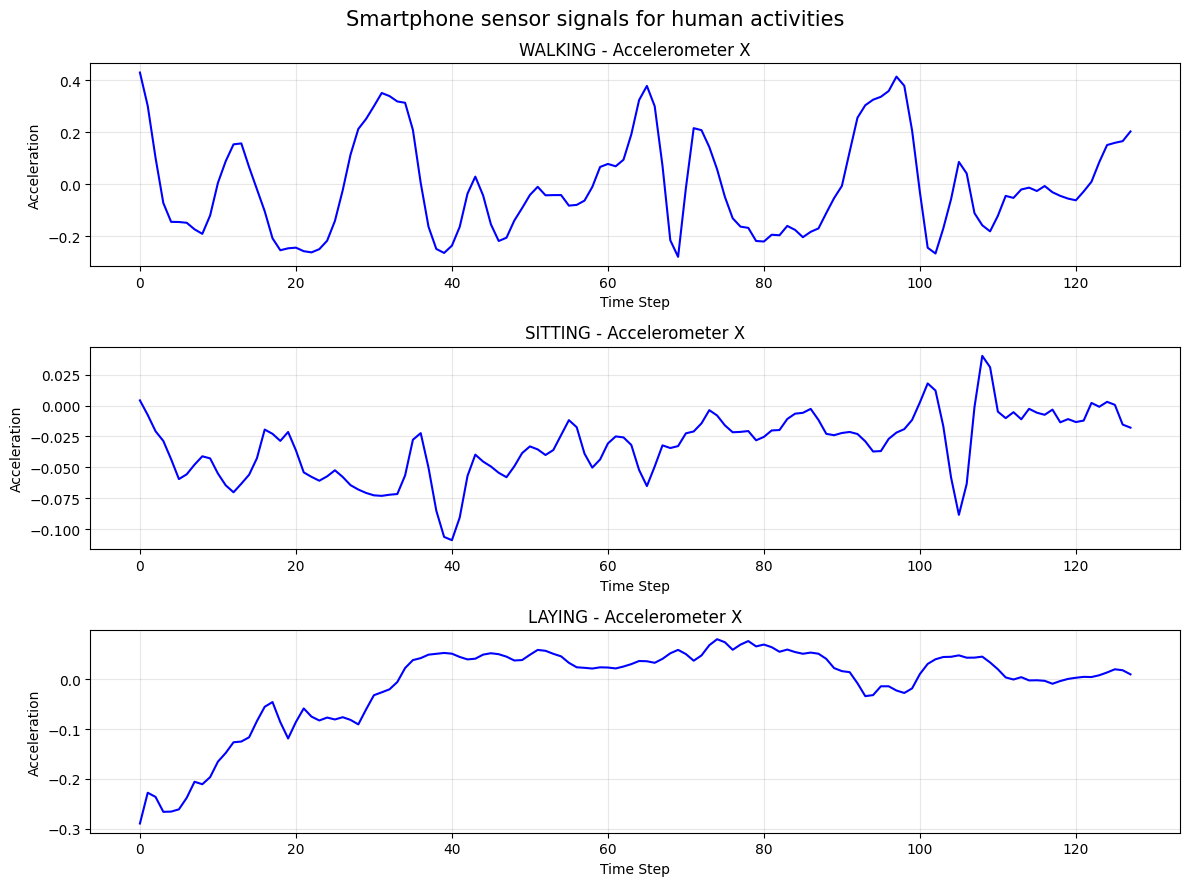

In [32]:
# Create the figures folder

# Training activity labels
train_labels = y_train.iloc[train_idx, 0].to_numpy()

# Select 3 activity
activities = { 1: "WALKING", 4: "SITTING",6: "LAYING"}

# Create graphs
fig, axes = plt.subplots(3, 1, figsize=(12, 9))

for ax, (activity_id, activity_name) in zip(axes, activities.items()):
    sample_index = np.where(train_labels == activity_id)[0][0]
    sensor_values = X_sequence_train[sample_index, :, 0]
    ax.plot(sensor_values,color="blue",linewidth=1.5)
    ax.set_title(f"{activity_name} - Accelerometer X")
    ax.set_xlabel("Time Step")
    ax.set_ylabel("Acceleration")
    ax.grid(True, alpha=0.3)

plt.suptitle("Smartphone sensor signals for human activities",fontsize=15)
plt.tight_layout()
# Saving
plt.savefig("figures/activity_sensor_signals.png",dpi=300,bbox_inches="tight")
plt.show()

## 6. Manual NumPy MLP

### 6.1 Feature Preparation


In [33]:
# Convert the 9 sensor channels into 18 summary features
def extract_features(X):
    means = np.mean(X, axis=1)
    stds = np.std(X, axis=1)
    return np.concatenate([means, stds], axis=1)

X_manual_train_raw = extract_features(X_sequence_train)
X_manual_val_raw = extract_features(X_sequence_val)

# Calculating mean and standard deviation on training set
feature_mean = X_manual_train_raw.mean(axis=0)
feat_std = X_manual_train_raw.std(axis=0)
feat_std = np.where(feat_std < 1e-8, 1.0, feat_std)

# Normalize the input features
X_manual_train = (X_manual_train_raw - feature_mean) / feat_std
X_manual_val = (X_manual_val_raw - feature_mean) / feat_std

# Convert activity labels 
y_manual_train = ( y_train.iloc[train_idx, 0].to_numpy(dtype=int) - 1)
y_manual_val = (y_train.iloc[val_idx, 0].to_numpy(dtype=int) - 1)


In [34]:
# Select 1500 examples for manual neural network training
rng = np.random.default_rng(42)
subset_indices = rng.choice(len(X_manual_train),size=min(1500, len(X_manual_train)),replace=False)
X_small = X_manual_train[subset_indices]
y_small = y_manual_train[subset_indices]
print("Input shape:", X_small.shape)
print("Labels shape:", y_small.shape)
print("Number of classes:", len(np.unique(y_small)))


Input shape: (1500, 18)
Labels shape: (1500,)
Number of classes: 6


### 6.2 Model Initialisation and Forward Pass


In [35]:
input_size = 18
hidden_size = 32
output_size = 6

# initialize weights for the hidden layer and biases for the hidden layer and output layer
W1 = rng.normal(0,np.sqrt(1 / input_size),size=(input_size, hidden_size))
W2 = rng.normal(0,np.sqrt(1 / hidden_size),size=(hidden_size, output_size))
b1 = np.zeros((1, hidden_size))
b2 = np.zeros((1, output_size))

In [36]:
print("W1 shape:", W1.shape)
print("b1 shape:", b1.shape)
print("W2 shape:", W2.shape)
print("b2 shape:", b2.shape)

W1 shape: (18, 32)
b1 shape: (1, 32)
W2 shape: (32, 6)
b2 shape: (1, 6)


In [37]:
# Forward Propagation
def softmax(z):
    z = z - np.max(z, axis=1, keepdims=True)
    exp_z = np.exp(z)
    return exp_z / np.sum(exp_z, axis=1, keepdims=True)

In [38]:
def forward_pass(X):
    z1 = X @ W1 + b1
    a1 = np.tanh(z1) # Tanh activation function
    z2 = a1 @ W2 + b2
    proba = softmax(z2) # Convert outputs for probabilities
    return z1, a1, proba

In [39]:
# Make predictions for first five samples
z1, a1, proba = forward_pass(X_small[:5])
print("Hidden layer shape:", a1.shape)
print("Prediction shape:", proba.shape)

print("\nPredicted probabilities:")
print(np.round(proba, 3))

print("\nPredicted activity class IDs:")
print(np.argmax(proba, axis=1) + 1)


Hidden layer shape: (5, 32)
Prediction shape: (5, 6)

Predicted probabilities:
[[0.146 0.13  0.101 0.202 0.188 0.234]
 [0.146 0.126 0.1   0.208 0.197 0.223]
 [0.251 0.23  0.109 0.148 0.152 0.109]
 [0.151 0.173 0.097 0.2   0.197 0.182]
 [0.125 0.188 0.103 0.224 0.193 0.168]]

Predicted activity class IDs:
[6 6 1 4 4]


In [40]:
# Calculate Initial Loss
def cross_entropy_loss(probabilities, labels):
    correct_probs = probabilities[ np.arange(len(labels)),labels]
    correct_probs = np.clip(correct_probs,1e-12,1.0)
    loss = -np.mean(np.log(correct_probs))
    return loss


# Calculate predictions for training subset
_, _, initial_predictions = forward_pass(X_small)

initial_loss = cross_entropy_loss(initial_predictions,y_small)
print("Initial Loss:", round(initial_loss, 4))

Initial Loss: 1.7176


In [41]:
# Verify probability calculations
print("Probabilities sum to 1:", np.allclose(initial_predictions.sum(axis=1),1.0))
print("Initial loss is finite:", np.isfinite(initial_loss))

Probabilities sum to 1: True
Initial loss is finite: True


### 6.3 Backpropagation and Model Training


In [42]:
# Manual Backpropagation

def backward_pass(X, y):
    # Forward propagation
    z1, a1, predictions = forward_pass(X)
    n = len(X)
    # Output layer gradient
    dz2 = predictions.copy()
    dz2[np.arange(n), y] -= 1
    dz2 /= n  
    dW2 = a1.T @ dz2
    db2 = np.sum(dz2, axis=0, keepdims=True)
    dz1 = (dz2 @ W2.T) * (1 - a1**2)
    dW1 = X.T @ dz1
    db1 = np.sum(dz1, axis=0, keepdims=True)
    return dW1, db1, dW2, db2

- If anyone wants to retrain the models, please delete the files in the `models` folder and rerun the notebook from the beginning.


In [43]:
learning_rate = 0.05
epochs = 150
batch_size = 64

manual_file = Path("models/manual_mlp_numpy.npz")
manual_loaded = manual_file.exists()

if manual_loaded:
    with np.load(manual_file, allow_pickle=False) as saved:
        W1 = saved["W1"].copy()
        b1 = saved["b1"].copy()
        W2 = saved["W2"].copy()
        b2 = saved["b2"].copy()
        feature_mean = saved["feature_mean"].copy()
        feat_std = saved["feature_std"].copy()
        train_losses = saved["train_losses"].tolist()
        val_losses = saved["val_losses"].tolist()
        initial_loss = float(saved["initial_loss"])
        learning_rate = float(saved["learning_rate"])
        batch_size = int(saved["batch_size"])
    X_manual_train = (X_manual_train_raw - feature_mean) / feat_std
    X_manual_val = (X_manual_val_raw - feature_mean) / feat_std
    X_small = X_manual_train[subset_indices]
    print("Loaded saved manual MLP.")
else:
    train_losses = []
    val_losses = []
    _, _, start_predictions = forward_pass(X_small)
    initial_loss = cross_entropy_loss(start_predictions, y_small)
    for epoch in range(epochs):
        indices = rng.permutation(len(X_small))
        X_shuffled = X_small[indices]
        y_shuffled = y_small[indices]

        for start in range(0, len(X_small), batch_size):
            X_batch = X_shuffled[start:start + batch_size]
            y_batch = y_shuffled[start:start + batch_size]

            dW1, db1, dW2, db2 = backward_pass(X_batch, y_batch)
            W1 -= learning_rate * dW1
            b1 -= learning_rate * db1
            W2 -= learning_rate * dW2
            b2 -= learning_rate * db2

        _, _, train_pred = forward_pass(X_small)
        train_loss = cross_entropy_loss(train_pred, y_small)

        _, _, val_pred = forward_pass(X_manual_val)
        val_loss = cross_entropy_loss(val_pred, y_manual_val)

        train_losses.append(train_loss)
        val_losses.append(val_loss)

        if (epoch + 1) % 25 == 0:
            print(f"Epoch {epoch + 1}/{epochs} | "
                f"Train Loss: {train_loss:.4f} | "
                f"Validation Loss: {val_loss:.4f}")

print("Initial Loss:", round(initial_loss, 4))
print("Final loss:", round(train_losses[-1], 4))
print("Actual epochs:", len(train_losses))


Loaded saved manual MLP.
Initial Loss: 1.7176
Final loss: 0.2005
Actual epochs: 150


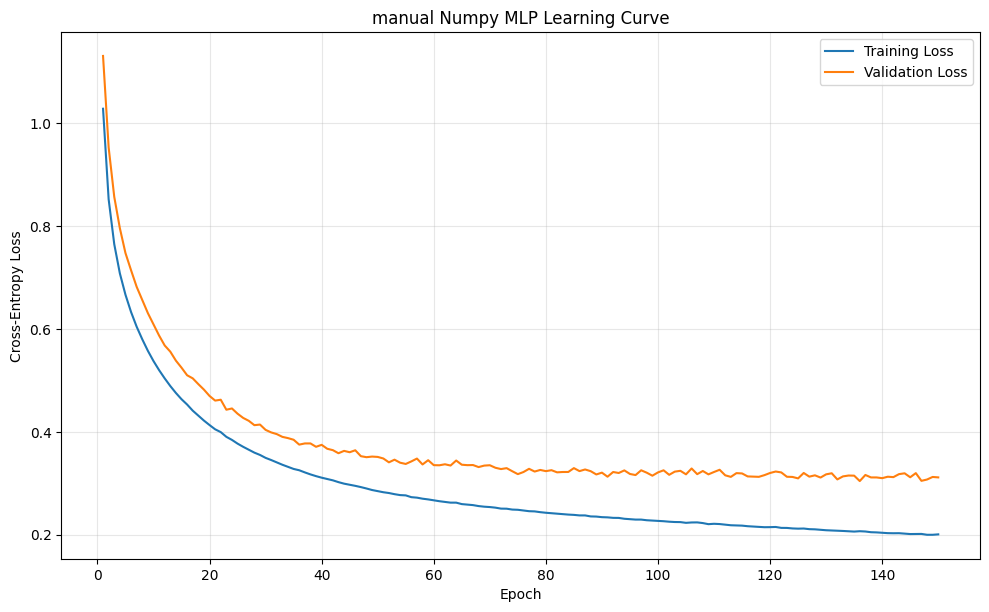

In [44]:
# Loss Curve
plt.figure(figsize=(10, 6))
plt.plot(range(1, len(train_losses) + 1),train_losses,label="Training Loss")
plt.plot(range(1, len(val_losses) + 1),val_losses,label="Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Cross-Entropy Loss")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.title("manual Numpy MLP Learning Curve")
plt.savefig("figures/manual_mlp_loss_curve.png",dpi=300)
plt.show()

In [45]:
Path("models").mkdir(exist_ok=True)

if not manual_loaded:
    np.savez("models/manual_mlp_numpy.npz", W1=W1,b1=b1,W2=W2,b2=b2,feature_mean=feature_mean,
        feature_std=feat_std,train_losses=np.array(train_losses),val_losses=np.array(val_losses),
        initial_loss=initial_loss,learning_rate=learning_rate, batch_size=batch_size, epochs_completed=len(train_losses))


### 6.4 Numerical Gradient Verification


In [46]:
# Use a small batch for checking
X_check = X_small[:4]
y_check = y_small[:4]

# Small perturbation value
epsilon = 1e-5
dW1, db1, dW2, db2 = backward_pass(X_check, y_check)

parameters = [("W1", W1, dW1),("b1", b1, db1),("W2", W2, dW2),("b2", b2, db2)]

results = []

In [47]:
for name, parameter, analytical_grad in parameters:

    indices = [(0, 0), (0, 1)]
    for idx in indices:
        original = parameter[idx]

        parameter[idx] = original + epsilon
        _, _, pred_plus = forward_pass(X_check)
        loss_plus = cross_entropy_loss(pred_plus, y_check)
        parameter[idx] = original - epsilon
        _, _, pred_minus = forward_pass(X_check)
        loss_minus = cross_entropy_loss( pred_minus, y_check)
        parameter[idx] = original
        numerical = (loss_plus - loss_minus) / (2 * epsilon)
        analytical = analytical_grad[idx]
        abs_error = abs(analytical - numerical)
        rel_error = abs_error / max(1e-8,abs(analytical) + abs(numerical))
        results.append([name,str(idx), analytical,numerical,abs_error,rel_error])

In [48]:
gradient_results = pd.DataFrame(results, columns=["Parameter","index","Analytical","Numerical","Absolute Error","Relative Error"])
display(gradient_results)

Path("results").mkdir(exist_ok=True)
gradient_results.to_csv("results/gradient_check.csv",index=False)
passed = ((gradient_results["Absolute Error"] < 1e-5) | (gradient_results["Relative Error"] < 1e-4)).all()

,Parameter,index,Analytical,Numerical,Absolute Error,Relative Error
0,W1,"(0, 0)",0.001297,0.001297,1.231459e-12,4.746938e-10
1,W1,"(0, 1)",-0.000302,-0.000302,4.057301e-12,6.726659e-09
2,b1,"(0, 0)",0.000805,0.000805,9.905404e-13,6.155688e-10
3,b1,"(0, 1)",-0.000426,-0.000426,5.084612e-12,5.973371e-09
4,W2,"(0, 0)",0.002567,0.002567,2.878095e-12,5.606330e-10
5,W2,"(0, 1)",-0.002465,-0.002465,3.036872e-13,6.160844e-11
6,b2,"(0, 0)",-0.003669,-0.003669,3.258937e-12,4.441181e-10
7,b2,"(0, 1)",0.003525,0.003525,4.015239e-12,5.695638e-10


In [49]:
print("Gradient check passed:", passed)

Gradient check passed: True


### 6.5 Tiny-Batch Learning Diagnosis


- If anyone wants to retrain the models, please delete the files in the `models` folder and rerun the notebook from the beginning.


In [50]:
tiny_indices = np.concatenate([
    np.where(y_small == class_id)[0][:2] for class_id in range(6)])
X_tiny = X_small[tiny_indices]
y_tiny = y_small[tiny_indices]
print("Tiny batch shape:", X_tiny.shape)
diagnostic_rng = np.random.default_rng(123)
V1 = diagnostic_rng.normal(0, np.sqrt(1 / 18), size=(18, 32))
c1 = np.zeros((1, 32))
V2 = diagnostic_rng.normal(0, np.sqrt(1 / 32), size=(32, 6))
c2 = np.zeros((1, 6))
def tiny_forward(X):
    hidden = np.tanh(X @ V1 + c1)
    probabilities = softmax(hidden @ V2 + c2)
    return hidden, probabilities
diagnostic_lr = 0.1
max_epochs = 2000
target_loss = 0.05
history = []
accuracy_history = []
n = len(X_tiny)
_, initial_probs = tiny_forward(X_tiny)
tiny_initial_loss = cross_entropy_loss(initial_probs, y_tiny)

tiny_file = Path("models/tiny_batch_diagnosis.npz")
if tiny_file.exists():
    with np.load(tiny_file, allow_pickle=False) as saved:
        V1 = saved["V1"].copy()
        c1 = saved["c1"].copy()
        V2 = saved["V2"].copy()
        c2 = saved["c2"].copy()
        history = saved["history"].tolist()
        accuracy_history = saved["accuracy_history"].tolist()
        tiny_initial_loss = float(saved["initial_loss"])
        actual_epochs = int(saved["actual_epochs"])
        diagnostic_lr = float(saved["learning_rate"])
        max_epochs = int(saved["max_epochs"])
        target_loss = float(saved["target_loss"])
    print("Loaded saved tiny-batch model and results.")
else:
    for epoch in range(max_epochs):
        hidden, probabilities = tiny_forward(X_tiny)

        # Calculate gradients
        dz2 = probabilities.copy()
        dz2[np.arange(n), y_tiny] -= 1
        dz2 /= n
        dV2 = hidden.T @ dz2
        dc2 = np.sum(dz2, axis=0, keepdims=True)

        dz1 = (dz2 @ V2.T) * (1 - hidden**2)
        dV1 = X_tiny.T @ dz1
        dc1 = np.sum(dz1, axis=0, keepdims=True)

        V1 -= diagnostic_lr * dV1
        c1 -= diagnostic_lr * dc1
        V2 -= diagnostic_lr * dV2
        c2 -= diagnostic_lr * dc2

        _, updated_probs = tiny_forward(X_tiny)
        current_loss = cross_entropy_loss(updated_probs, y_tiny)
        accuracy = np.mean(np.argmax(updated_probs, axis=1) == y_tiny)

        history.append(current_loss)
        accuracy_history.append(accuracy)

        # Stop once the model fits all 12 examples with low loss
        if current_loss < target_loss and accuracy == 1.0:
            break
    actual_epochs = epoch + 1
    tiny_file.parent.mkdir(exist_ok=True)
    np.savez(tiny_file, V1=V1, c1=c1, V2=V2, c2=c2,
             history=np.array(history), accuracy_history=np.array(accuracy_history),
             initial_loss=tiny_initial_loss, actual_epochs=actual_epochs,
             learning_rate=diagnostic_lr, max_epochs=max_epochs, target_loss=target_loss)

print("\nNumerical Diagnosis results")
print("Initial loss:", round(tiny_initial_loss, 6))
print("Final loss:", round(history[-1], 6))
print("Final accuracy:", round(accuracy_history[-1] * 100, 2), "%")
print("Actual epochs:", actual_epochs)
print("Learning rate:", diagnostic_lr)
print("Maximum epochs:", max_epochs)
if history[-1] < target_loss and accuracy_history[-1] == 1.0:
    print("Tiny-batch overfitting check PASSED")
else:
    print("Tiny-batch target not reached; investigate convergence")


Tiny batch shape: (12, 18)
Loaded saved tiny-batch model and results.

Numerical Diagnosis results
Initial loss: 1.646648
Final loss: 0.049848
Final accuracy: 100.0 %
Actual epochs: 406
Learning rate: 0.1
Maximum epochs: 2000
Tiny-batch overfitting check PASSED


### 6.6 Experiment Summary


In [51]:

summary = { "model": "Manual NumPy MLP","dataset": "UCI HAR","input_features": 18,
"hidden_neurons": 32,"output_classes": 6,"hidden_activation": "tanh", "output_activation": "softmax",
"loss_function": "cross_entropy"}


In [52]:
# Training results
summary["main_training"] = {"learning_rate": float(learning_rate),
"batch_size": int(batch_size), "epochs_completed": int(len(train_losses)),
    "initial_loss": float(initial_loss),"final_training_loss": float(train_losses[-1]),"final_validation_loss": float(val_losses[-1])}

In [53]:
# Gradient check results
summary["gradient_check"] = {
    "epsilon": 1e-5,"entries_checked": len(gradient_results),"passed": bool(passed),
    "max_absolute_error": float(gradient_results["Absolute Error"].max()),
    "max_relative_error": float(gradient_results["Relative Error"].max())}


In [54]:
# Tiny-batch results
summary["tiny_batch_diagnosis"] = {"samples": 12,"learning_rate": diagnostic_lr,"max_epochs": max_epochs,
    "actual_epochs": actual_epochs,"stopping_rule": "loss < 0.05 and accuracy = 100%",
    "initial_loss": float(tiny_initial_loss),"final_loss": float(history[-1]),"final_accuracy": float(accuracy_history[-1])}


In [55]:
# Save and display the summary
with open("results/manual_mlp_summary.json", "w", encoding="utf-8") as file:
    json.dump(summary, file, indent=4)

print("T2 Experimental Summary")
print(json.dumps(summary, indent=4))
print("\nSummary saved successfully!")


T2 Experimental Summary
{
    "model": "Manual NumPy MLP",
    "dataset": "UCI HAR",
    "input_features": 18,
    "hidden_neurons": 32,
    "output_classes": 6,
    "hidden_activation": "tanh",
    "output_activation": "softmax",
    "loss_function": "cross_entropy",
    "main_training": {
        "learning_rate": 0.05,
        "batch_size": 64,
        "epochs_completed": 150,
        "initial_loss": 1.717613987208106,
        "final_training_loss": 0.2004806849951492,
        "final_validation_loss": 0.31130934134810445
    },
    "gradient_check": {
        "epsilon": 1e-05,
        "entries_checked": 8,
        "passed": true,
        "max_absolute_error": 5.08461247281447e-12,
        "max_relative_error": 6.7266585226921946e-09
    },
    "tiny_batch_diagnosis": {
        "samples": 12,
        "learning_rate": 0.1,
        "max_epochs": 2000,
        "actual_epochs": 406,
        "stopping_rule": "loss < 0.05 and accuracy = 100%",
        "initial_loss": 1.6466484860143737,
   

## 7. Non-Neural Baseline: Logistic Regression

Logistic regression used L-BFGS, C = 1 and up to 1,500 iterations on 1,152 flattened values. Its linear class scores provide a reference for the benefit of nonlinear features.


In [56]:
print('Training:', X_sequence_train.shape)
print('Validation:', X_sequence_val.shape)
y_lr_train = y_train.iloc[train_idx, 0].to_numpy(dtype=int) - 1
y_lr_val = y_train.iloc[val_idx, 0].to_numpy(dtype=int) - 1


Training: (5551, 128, 9)
Validation: (1801, 128, 9)


In [57]:
from sklearn.preprocessing import StandardScaler
scaler_file = Path("models/sensor_scaler.joblib")
if scaler_file.exists():
    st_scaler = joblib.load(scaler_file)
else:
    st_scaler = StandardScaler()
    st_scaler.fit(X_sequence_train.reshape(-1, 9))
    scaler_file.parent.mkdir(exist_ok=True)
    joblib.dump(st_scaler, scaler_file)

X_st_train = st_scaler.transform(X_sequence_train.reshape(-1, 9)).reshape(-1, 128, 9)
X_st_val = st_scaler.transform(X_sequence_val.reshape(-1, 9)).reshape(-1, 128, 9)


c:\Users\chali\AppData\Local\Programs\Python\Python311\Lib\site-packages\sklearn\base.py:380: InconsistentVersionWarning: Trying to unpickle estimator StandardScaler from version 1.9.1 when using version 1.6.1. This might lead to breaking code or invalid results. Use at your own risk. For more info please refer to:
https://scikit-learn.org/stable/model_persistence.html#security-maintainability-limitations
  warnings.warn(


In [58]:
X_lr_train = X_st_train.reshape(-1, 1152)
X_lr_val = X_st_val.reshape(-1, 1152)
assert np.isfinite(X_lr_train).all()
assert np.isfinite(X_lr_val).all()



In [59]:
from sklearn.linear_model import LogisticRegression
import time

lr_model = LogisticRegression(C=1.0, max_iter=1500, solver='lbfgs', random_state=42)


- If anyone wants to retrain the models, please delete the files in the `models` folder and rerun the notebook from the beginning.


In [60]:
lr_file = Path("models/logistic_regression.joblib")
lr_loaded = lr_file.exists()
if lr_loaded:
    lr_model = joblib.load(lr_file)
    lr_meta_file = Path("results/logistic_regression_validation.json")
    lr_time = None
    if lr_meta_file.exists():
        with lr_meta_file.open(encoding="utf-8") as file:
            lr_time = json.load(file).get("training_time_seconds")
    print("Loaded saved logistic regression model.")
else:
    print('Training baseline model...')
    start_time = time.perf_counter()
    lr_model.fit(X_lr_train, y_lr_train)
    lr_time = time.perf_counter() - start_time

if lr_time is None:
    print("Training time: not recorded for this saved model")
else:
    print('Training time:', round(lr_time, 2), 'seconds')


Loaded saved logistic regression model.
Training time: 98.13 seconds


c:\Users\chali\AppData\Local\Programs\Python\Python311\Lib\site-packages\sklearn\base.py:380: InconsistentVersionWarning: Trying to unpickle estimator LogisticRegression from version 1.9.1 when using version 1.6.1. This might lead to breaking code or invalid results. Use at your own risk. For more info please refer to:
https://scikit-learn.org/stable/model_persistence.html#security-maintainability-limitations
  warnings.warn(


In [61]:
from sklearn.metrics import accuracy_score, f1_score, classification_report

lr_pred = lr_model.predict(X_lr_val)
lr_acc = accuracy_score(y_lr_val, lr_pred)
lr_f1 = f1_score(y_lr_val, lr_pred, average='macro', zero_division=0)

In [62]:
print('Logistic regression Validation Results')
print('Accuracy:', round(lr_acc, 4))
print('Macro F1:', round(lr_f1, 4))


Logistic regression Validation Results
Accuracy: 0.6519
Macro F1: 0.6121


In [63]:
act_names = ['WALKING', 'WALKING_UPSTAIRS', 'WALKING_DOWNSTAIRS', 'SITTING', 'STANDING', 'LAYING']
print('\nClassification Report:')
print(classification_report(y_lr_val, lr_pred, labels=range(6), target_names=act_names, zero_division=0))



Classification Report:
                    precision    recall  f1-score   support

           WALKING       0.46      0.27      0.34       338
  WALKING_UPSTAIRS       0.62      0.44      0.51       276
WALKING_DOWNSTAIRS       0.40      0.26      0.32       242
           SITTING       0.73      1.00      0.84       293
          STANDING       0.54      0.86      0.66       321
            LAYING       1.00      0.99      1.00       331

          accuracy                           0.65      1801
         macro avg       0.62      0.64      0.61      1801
      weighted avg       0.63      0.65      0.62      1801



In [64]:
Path('models').mkdir(exist_ok=True)

if not lr_loaded:
    joblib.dump(lr_model, 'models/logistic_regression.joblib')


lr_results = {"model": "Logistic Regression", "input": "128x9 sensor windows flattened to 1152",
    "C": 1.0,"max_iter": 1500, "solver": "lbfgs", "primary_metric": "macro_f1", "validation_accuracy": float(lr_acc), "validation_macro_f1": float(lr_f1),
    "training_time_seconds": float(lr_time) if lr_time is not None else None,"test_evaluated": False}


In [65]:
with open("results/logistic_regression_validation.json", "w", encoding="utf-8") as file:
    json.dump(lr_results, file, indent=4)

print('Baseline model saved successfully!')
print('Sensor scaler saved successfully!')
print('Validation results saved successfully!')


Baseline model saved successfully!
Sensor scaler saved successfully!
Validation results saved successfully!


## 8. TensorFlow MLP

### 8.1 Framework and Input Preparation




In [66]:
import sys
import tensorflow as tf


In [67]:
dataset_path = Path('data/UCI HAR Dataset')
saved_split = np.load('data/splits/subject_split_seed42.npz')
train_idx = saved_split['train_indices']
val_idx = saved_split['validation_indices']

def load_xyz(split, sensor_name):
    folder = dataset_path / split / "Inertial Signals"
    axes = [np.loadtxt(folder / f"{sensor_name}_{axis}_{split}.txt",dtype=np.float32)
        for axis in ["x", "y", "z"] ]
    return np.stack(axes, axis=2)


In [68]:
body_acc = load_xyz('train', 'body_acc')
total_acc = load_xyz('train', 'total_acc')
gyro = load_xyz('train', 'body_gyro')
gravity = total_acc - body_acc
X_full = np.concatenate([body_acc, gravity, gyro], axis=2)
y_full = np.loadtxt(dataset_path / 'train/y_train.txt', dtype=np.int32) - 1


In [69]:
st_scaler = joblib.load('models/sensor_scaler.joblib')
X_train_seq = X_full[train_idx]
X_val_seq = X_full[val_idx]
X_mlp_train = st_scaler.transform(X_train_seq.reshape(-1, 9)).reshape(-1, 1152).astype(np.float32)
X_mlp_val = st_scaler.transform(X_val_seq.reshape(-1, 9)).reshape(-1, 1152).astype(np.float32)
y_mlp_train = y_full[train_idx]
y_mlp_val = y_full[val_idx]

c:\Users\chali\AppData\Local\Programs\Python\Python311\Lib\site-packages\sklearn\base.py:380: InconsistentVersionWarning: Trying to unpickle estimator StandardScaler from version 1.9.1 when using version 1.6.1. This might lead to breaking code or invalid results. Use at your own risk. For more info please refer to:
https://scikit-learn.org/stable/model_persistence.html#security-maintainability-limitations
  warnings.warn(


In [70]:
print('Training shape:', X_mlp_train.shape)
print('Validation shape:', X_mlp_val.shape)
print('Training labels:', y_mlp_train.shape)
print('Validation labels:', y_mlp_val.shape)

Training shape: (5551, 1152)
Validation shape: (1801, 1152)
Training labels: (5551,)
Validation labels: (1801,)


### 8.2 Model Architecture and Training

Both models used sparse categorical cross-entropy and Adam at 0.001 with shuffled batches of 64.

ModelCheckpoint retained minimum validation loss. Early stopping allowed five epochs without improvement within a 30-epoch cap.


In [71]:
from tensorflow.keras import Sequential
from tensorflow.keras.layers import Input, Dense, Dropout
from tensorflow.keras.optimizers import Adam

tf.keras.utils.set_random_seed(42)


In [72]:
mlp = Sequential([ Input(shape=(1152,)),
    Dense(128, activation="relu"),
    Dropout(0.25),
    Dense(64, activation="relu"),
    Dense(6, activation="softmax")])

mlp.compile(optimizer=Adam(learning_rate=0.001),loss="sparse_categorical_crossentropy",metrics=["accuracy"])
mlp.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 128)            │       147,584 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 6)              │           390 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 156,230 (610.27 KB)

 Trainable params: 156,230 (610.27 KB)

 Non-trainable params: 0 (0.00 B)

In [73]:
from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint
import time

Path('models').mkdir(exist_ok=True)

mlp_ckpt = ModelCheckpoint( filepath="models/mlp_seed42.keras",monitor="val_loss",mode="min",save_best_only=True,verbose=1)
mlp_stop = EarlyStopping(monitor='val_loss', patience=5, mode='min', restore_best_weights=True)

- If anyone wants to retrain the models, please delete the files in the `models` folder and rerun the notebook from the beginning.


In [74]:
mlp_file = Path("models/mlp_seed42.keras")
mlp_loaded = mlp_file.exists()
mlp_saved_scores = {}
if mlp_loaded:
    mlp = tf.keras.models.load_model(mlp_file)
    mlp_hist_file = Path("results/mlp_history_seed42.csv")
    if not mlp_hist_file.exists():
        raise FileNotFoundError("Restore results/mlp_history_seed42.csv, or delete models/mlp_seed42.keras and rerun from the beginning to retrain.")
    mlp_hist = tf.keras.callbacks.History()
    mlp_hist.history = pd.read_csv(mlp_hist_file).to_dict(orient="list")
    mlp_meta_file = Path("results/mlp_validation_seed42.json")
    if mlp_meta_file.exists():
        with mlp_meta_file.open(encoding="utf-8") as file:
            mlp_saved_scores = json.load(file)
    mlp_time = mlp_saved_scores.get("training_time_seconds")
    print("Loaded saved MLP model and training history.")
else:
    print('Starting MLP training...')
    start_time = time.perf_counter()
    mlp_hist = mlp.fit(X_mlp_train, y_mlp_train, validation_data=(X_mlp_val, y_mlp_val),epochs=30, batch_size=64, callbacks=[mlp_stop, mlp_ckpt],verbose=1)
    mlp_time = time.perf_counter() - start_time

print('Epochs Completed:', len(mlp_hist.history['loss']))
if mlp_time is None:
    print("Training time: not recorded for this saved model")
else:
    print('Training Time:', round(mlp_time, 2), 'seconds')


Loaded saved MLP model and training history.
Epochs Completed: 9
Training Time: 42.43 seconds


### 8.3 Learning Curves and Validation Evaluation


In [75]:
mlp_hist_df = pd.DataFrame(mlp_hist.history)
if not mlp_loaded:
    mlp_hist_df.to_csv('results/mlp_history_seed42.csv', index=False)

epoch_numbers = range(1, len(mlp_hist_df) + 1)


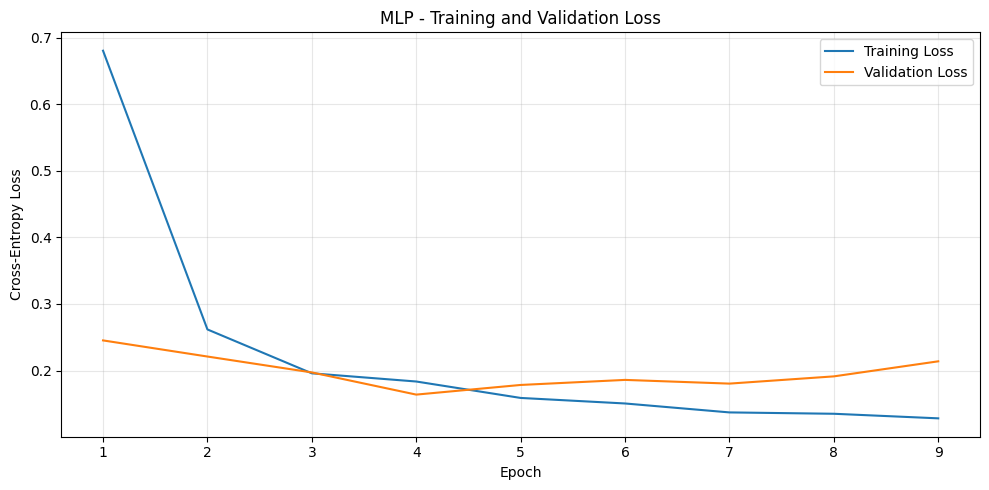

In [76]:
plt.figure(figsize=(10, 5))
plt.plot(epoch_numbers, mlp_hist_df['loss'], label='Training Loss')
plt.plot(epoch_numbers, mlp_hist_df['val_loss'], label='Validation Loss')
plt.title('MLP - Training and Validation Loss')
plt.xlabel('Epoch')
plt.ylabel('Cross-Entropy Loss')
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig('figures/mlp_loss_curve.png', dpi=300)
plt.show()


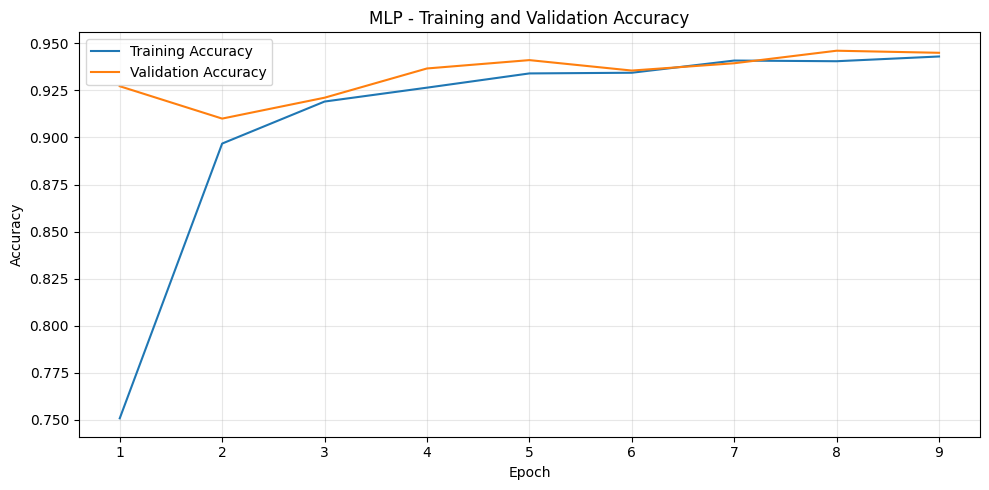

In [77]:
plt.figure(figsize=(10, 5))
plt.plot(epoch_numbers, mlp_hist_df['accuracy'], label='Training Accuracy')
plt.plot(epoch_numbers, mlp_hist_df['val_accuracy'], label='Validation Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.title('MLP - Training and Validation Accuracy')
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig('figures/mlp_accuracy_curve.png', dpi=300)
plt.show()


In [78]:
mlp_hist_df = pd.DataFrame(mlp_hist.history)
if not mlp_loaded:
    mlp_hist_df.to_csv('results/mlp_history_seed42.csv', index=False)

epoch_num = range(1, len(mlp_hist_df) + 1)


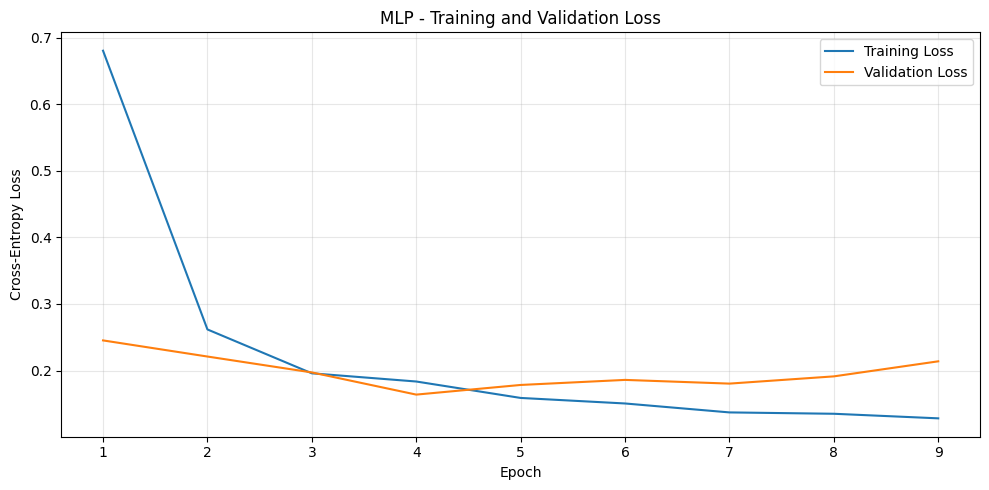

In [79]:
plt.figure(figsize=(10, 5))
plt.plot(epoch_num, mlp_hist_df['loss'], label='Training Loss')
plt.plot(epoch_num, mlp_hist_df['val_loss'], label='Validation Loss')
plt.xlabel('Epoch')
plt.ylabel('Cross-Entropy Loss')
plt.title('MLP - Training and Validation Loss')
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig('figures/mlp_loss_curve.png', dpi=300)
plt.show()


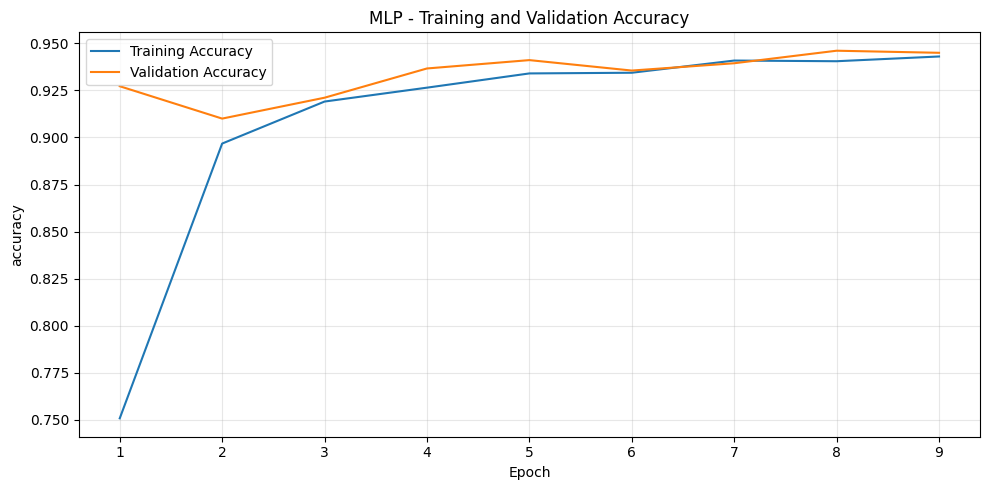

In [80]:
plt.figure(figsize=(10, 5))
plt.plot(epoch_num, mlp_hist_df['accuracy'], label='Training Accuracy')
plt.plot(epoch_num, mlp_hist_df['val_accuracy'], label='Validation Accuracy')
plt.title('MLP - Training and Validation Accuracy')
plt.xlabel('Epoch')
plt.ylabel('accuracy')
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig('figures/mlp_accuracy_curve.png', dpi=300)
plt.show()


In [81]:
import platform
import sklearn
from tensorflow.keras.models import load_model

In [82]:
mlp_best = load_model('models/mlp_seed42.keras')
mlp_probs = mlp_best.predict(X_mlp_val, verbose=0)
mlp_pred = np.argmax(mlp_probs, axis=1)
mlp_acc = accuracy_score(y_mlp_val, mlp_pred)
mlp_f1 = f1_score(y_mlp_val, mlp_pred, average='macro', zero_division=0)
act_names = ['WALKING', 'WALKING_UPSTAIRS', 'WALKING_DOWNSTAIRS', 'SITTING', 'STANDING', 'LAYING']


In [83]:
print('MLP Validation Results')
print('Accuracy:', round(mlp_acc, 4))
print('Macro F1:', round(mlp_f1, 4))
print('\nClassification Report:')
print(classification_report(y_mlp_val, mlp_pred,labels=list(range(6)),target_names=act_names,zero_division=0))

MLP Validation Results
Accuracy: 0.9367
Macro F1: 0.9358

Classification Report:
                    precision    recall  f1-score   support

           WALKING       0.99      0.95      0.97       338
  WALKING_UPSTAIRS       0.97      0.92      0.94       276
WALKING_DOWNSTAIRS       0.92      0.95      0.94       242
           SITTING       0.84      0.90      0.87       293
          STANDING       0.90      0.88      0.89       321
            LAYING       1.00      1.00      1.00       331

          accuracy                           0.94      1801
         macro avg       0.94      0.94      0.94      1801
      weighted avg       0.94      0.94      0.94      1801



In [84]:
report = classification_report(y_mlp_val,mlp_pred,labels=list(range(6)),target_names=act_names,output_dict=True,zero_division=0)
pd.DataFrame(report).T.to_csv('results/mlp_classification_report_seed42.csv')

In [85]:
mlp_scores = { "model": "TensorFlow MLP","seed": 42,"input_features": 1152,
    "hidden_layers": [128, 64],"dropout": 0.25,"learning_rate": 0.001,"batch_size": 64,
    "max_epochs": 30,"actual_epochs": len(mlp_hist_df),"early_stopping_patience": 5,"checkpoint_selection": "minimum validation loss",
    "primary_metric": "macro_f1","validation_accuracy": float(mlp_acc),"validation_macro_f1": float(mlp_f1),
    "parameter_count": int(mlp_best.count_params()),"training_time_seconds": float(mlp_time) if mlp_time is not None else None,"tensorflow_version": tf.__version__,"sklearn_version": sklearn.__version__,
    "python_version": platform.python_version(),"checkpoint": "models/mlp_seed42.keras","test_evaluated": False}

if mlp_loaded and mlp_saved_scores:
    mlp_scores = dict(mlp_saved_scores)
    mlp_scores["validation_accuracy"] = float(mlp_acc)
    mlp_scores["validation_macro_f1"] = float(mlp_f1)

with open("results/mlp_validation_seed42.json","w",encoding="utf-8") as file:
    json.dump(mlp_scores, file, indent=4)
print('\nMLP results saved')


MLP results saved


### 8.4 Baseline Comparison


In [86]:
with open("results/logistic_regression_validation.json","r",encoding="utf-8") as file:
    lr_results = json.load(file)

comparison = pd.DataFrame({"Model": ["Logistic Regression","TensorFlow MLP"],
    "Validation Accuracy": [lr_results["validation_accuracy"],mlp_scores["validation_accuracy"]],
    "Validation Macro F1": [lr_results["validation_macro_f1"],mlp_scores["validation_macro_f1"]]})

display(comparison)
comparison.to_csv('results/baseline_vs_mlp.csv', index=False)
print('Model comparison saved')


,Model,Validation Accuracy,Validation Macro F1
0,Logistic Regression,0.651860,0.612095
1,TensorFlow MLP,0.936702,0.935819


Model comparison saved


## 9. Elman RNN

### 9.1 Input Preparation and Model Training

The Elman RNN shares weights across time and passes a 32-value state to the next step.


In [87]:
X_rnn_train = st_scaler.transform(X_train_seq.reshape(-1, 9)).reshape(-1, 128, 9).astype(np.float32)
X_rnn_val = st_scaler.transform(X_val_seq.reshape(-1, 9)).reshape(-1, 128, 9).astype(np.float32)
y_rnn_train = y_mlp_train.astype(np.int32)
y_rnn_val = y_mlp_val.astype(np.int32)

In [88]:
print('RNN Training:', X_rnn_train.shape)
print('RNN Validation:', X_rnn_val.shape)
print('Training Labels:', y_rnn_train.shape)
print('Validation Labels:', y_rnn_val.shape)
assert X_rnn_train.shape[1:] == (128, 9)
assert X_rnn_val.shape[1:] == (128, 9)
print('RNN data preparation successful!')

RNN Training: (5551, 128, 9)
RNN Validation: (1801, 128, 9)
Training Labels: (5551,)
Validation Labels: (1801,)
RNN data preparation successful!


In [89]:
from tensorflow.keras.layers import SimpleRNN
tf.keras.utils.set_random_seed(42)

In [90]:
rnn = Sequential([Input(shape=(128, 9)),
    SimpleRNN(32,activation="tanh",return_sequences=False),
    Dense(64, activation="relu"),
    Dropout(0.25),
    Dense(6, activation="softmax")])

rnn.compile(optimizer=Adam(learning_rate=0.001),loss="sparse_categorical_crossentropy",metrics=["accuracy"])
rnn.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ simple_rnn (SimpleRNN)          │ (None, 32)             │         1,344 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 64)             │         2,112 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 6)              │           390 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 3,846 (15.02 KB)

 Trainable params: 3,846 (15.02 KB)

 Non-trainable params: 0 (0.00 B)

In [91]:
Path('models').mkdir(exist_ok=True)
rnn_ckpt = ModelCheckpoint("models/rnn_seed42.keras",monitor="val_loss",mode="min",save_best_only=True,verbose=1)
rnn_stop = EarlyStopping(monitor='val_loss', patience=5, mode='min', restore_best_weights=True)

- If anyone wants to retrain the models, please delete the files in the `models` folder and rerun the notebook from the beginning.


In [92]:
rnn_file = Path("models/rnn_seed42.keras")
rnn_loaded = rnn_file.exists()
rnn_saved_scores = {}
if rnn_loaded:
    rnn = tf.keras.models.load_model(rnn_file)
    rnn_hist_file = Path("results/rnn_history_seed42.csv")
    if not rnn_hist_file.exists():
        raise FileNotFoundError("Restore results/rnn_history_seed42.csv, or delete models/rnn_seed42.keras and rerun from the beginning to retrain.")
    rnn_hist = tf.keras.callbacks.History()
    rnn_hist.history = pd.read_csv(rnn_hist_file).to_dict(orient="list")
    rnn_meta_file = Path("results/rnn_validation_seed42.json")
    if rnn_meta_file.exists():
        with rnn_meta_file.open(encoding="utf-8") as file:
            rnn_saved_scores = json.load(file)
    rnn_time = rnn_saved_scores.get("training_time_seconds")
    print("Loaded saved RNN model and training history.")
else:
    start_time = time.perf_counter()
    rnn_hist = rnn.fit(X_rnn_train,y_rnn_train,validation_data=(X_rnn_val, y_rnn_val),epochs=30,batch_size=64, callbacks=[rnn_ckpt,rnn_stop],verbose=1)
    rnn_time = time.perf_counter() - start_time

print('\nRNN Training Completed!')
print('Epochs Completed:', len(rnn_hist.history['loss']))
if rnn_time is None:
    print("Training time: not recorded for this saved model")
else:
    print('Training Time:', round(rnn_time, 2), 'seconds')


Loaded saved RNN model and training history.

RNN Training Completed!
Epochs Completed: 27
Training Time: 134.76 seconds


### 9.2 Learning Curves and Validation Evaluation


In [93]:
rnn_hist_df = pd.DataFrame(rnn_hist.history)
if not rnn_loaded:
    rnn_hist_df.to_csv('results/rnn_history_seed42.csv', index=False)

epoch_numbers = range(1, len(rnn_hist_df) + 1)


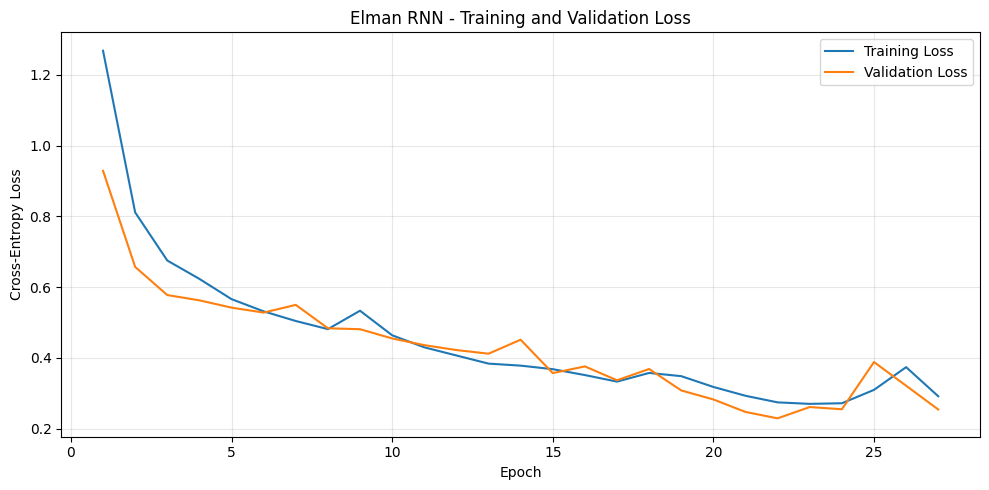

In [94]:
plt.figure(figsize=(10, 5))
plt.plot(epoch_numbers, rnn_hist_df['loss'], label='Training Loss')
plt.plot(epoch_numbers, rnn_hist_df['val_loss'], label='Validation Loss')
plt.xlabel('Epoch')
plt.ylabel('Cross-Entropy Loss')
plt.legend()
plt.title('Elman RNN - Training and Validation Loss')
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig('figures/rnn_loss_curve.png', dpi=300)
plt.show()

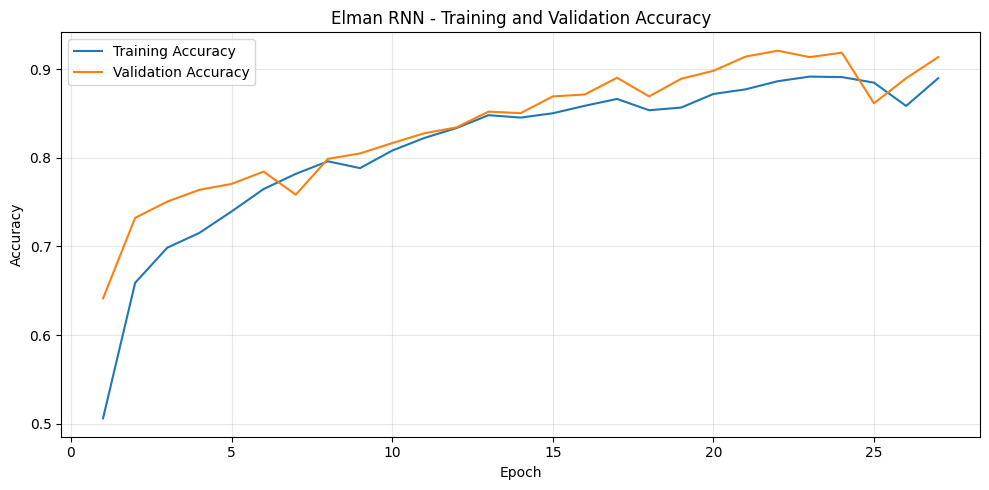

In [95]:
plt.figure(figsize=(10, 5))
plt.plot(epoch_numbers, rnn_hist_df['accuracy'], label='Training Accuracy')
plt.plot(epoch_numbers, rnn_hist_df['val_accuracy'], label='Validation Accuracy')
plt.title('Elman RNN - Training and Validation Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig('figures/rnn_accuracy_curve.png', dpi=300)
plt.show()

In [96]:
rnn_best = load_model('models/rnn_seed42.keras')
rnn_probs = rnn_best.predict(X_rnn_val, verbose=0)
rnn_pred = np.argmax(rnn_probs, axis=1)
rnn_acc = accuracy_score(y_rnn_val, rnn_pred)
rnn_f1 = f1_score(y_rnn_val, rnn_pred, average='macro', zero_division=0)
act_names = ['WALKING', 'WALKING_UPSTAIRS', 'WALKING_DOWNSTAIRS', 'SITTING', 'STANDING', 'LAYING']
print('RNN Validation Results')


RNN Validation Results


In [97]:
print('Accuracy:', round(rnn_acc, 4))
print('Macro F1:', round(rnn_f1, 4))
print('\nClassification Report:')
print(classification_report(y_rnn_val,rnn_pred,labels=range(6),target_names=act_names,zero_division=0))
report = classification_report(y_rnn_val,rnn_pred,labels=range(6),target_names=act_names,output_dict=True,zero_division=0)

Accuracy: 0.9212
Macro F1: 0.9184

Classification Report:
                    precision    recall  f1-score   support

           WALKING       0.77      0.91      0.83       338
  WALKING_UPSTAIRS       0.86      0.66      0.75       276
WALKING_DOWNSTAIRS       0.95      0.96      0.95       242
           SITTING       0.99      0.98      0.99       293
          STANDING       0.99      0.99      0.99       321
            LAYING       1.00      1.00      1.00       331

          accuracy                           0.92      1801
         macro avg       0.93      0.92      0.92      1801
      weighted avg       0.92      0.92      0.92      1801



In [98]:
pd.DataFrame(report).T.to_csv('results/rnn_classification_report_seed42.csv')
pd.DataFrame({"training_file_row": val_idx,"actual_class": y_rnn_val,"predicted_class": rnn_pred,"confidence": rnn_probs.max(axis=1)}).to_csv("results/rnn_predictions_seed42.csv",index=False)

In [99]:
rnn_scores = {"model": "Elman SimpleRNN","seed": 42,"input_shape": [128, 9],"rnn_units": 32,"dense_units": 64,"dropout": 0.25,"optimizer": "adam",
    "learning_rate": 0.001,"batch_size": 64,"max_epochs": 30,"epochs_completed": len(rnn_hist_df),"early_stopping_patience": 5,"checkpoint_selection": "minimum validation loss",
    "primary_metric": "macro_f1","validation_accuracy": float(rnn_acc),"validation_macro_f1": float(rnn_f1),"parameter_count": int(rnn_best.count_params()),"training_time_seconds": float(rnn_time) if rnn_time is not None else None,
    "tensorflow_version": tf.__version__,"python_version": platform.python_version(),"checkpoint": "models/rnn_seed42.keras","test_evaluated": False}

if rnn_loaded and rnn_saved_scores:
    rnn_scores = dict(rnn_saved_scores)
    rnn_scores["validation_accuracy"] = float(rnn_acc)
    rnn_scores["validation_macro_f1"] = float(rnn_f1)

with open("results/rnn_validation_seed42.json","w",encoding="utf-8") as file:
    json.dump(rnn_scores, file, indent=4)

## 10. Comparison of the Three Models


In [100]:
result_files = ["results/logistic_regression_validation.json","results/mlp_validation_seed42.json","results/rnn_validation_seed42.json"]
model_names = ['Logistic Regression', 'TensorFlow MLP', 'Elman RNN']
records = []
for name, filename in zip(model_names, result_files):
    with open(filename, "r", encoding="utf-8") as f:
        result = json.load(f)
    records.append({
        "Model": name,
        "Validation Accuracy": result["validation_accuracy"],
        "Validation Macro F1": result["validation_macro_f1"]})


In [101]:
comparison_df = pd.DataFrame(records)
comparison_df = comparison_df.sort_values('Validation Macro F1', ascending=False)
display(comparison_df)
comparison_df.to_csv('results/three_model_comparison.csv', index=False)
print('Validation comparison saved successfully!')

,Model,Validation Accuracy,Validation Macro F1
1,TensorFlow MLP,0.936702,0.935819
2,Elman RNN,0.921155,0.918432
0,Logistic Regression,0.651860,0.612095


Validation comparison saved successfully!


## 11. Controlled Experiments

### 11.1 Configuration and Three-Seed Evaluation

The main budget was one configuration per architecture at each of three seeds, plus three dropout ablations.


In [102]:
import gc
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
Path('models').mkdir(exist_ok=True)

In [103]:
SEEDS = [42, 123, 2026]
MAX_EPOCHS = 30
BATCH_SIZE = 64
LEARNING_RATE = 0.001
PATIENCE = 5

In [104]:
assert X_mlp_train.shape[1] == 1152
assert X_rnn_train.shape[1:] == (128, 9)
assert len(y_mlp_train) == len(y_rnn_train)
assert np.array_equal(y_mlp_train, y_rnn_train)
assert np.array_equal(y_mlp_val, y_rnn_val)
print('Experiment configuration ready!')
print('Random seeds:', SEEDS)
print('MLP training:', X_mlp_train.shape)
print('RNN training:', X_rnn_train.shape)
print('Validation samples:', len(y_mlp_val))

Experiment configuration ready!
Random seeds: [42, 123, 2026]
MLP training: (5551, 1152)
RNN training: (5551, 128, 9)
Validation samples: 1801


In [105]:
def build_experiment_model(architecture, dropout=0.25):
    if architecture == "MLP":
        model = Sequential([Input(shape=(1152,)),
            Dense(128, activation="relu"),
            Dropout(dropout),
            Dense(64, activation="relu"),
            Dense(6, activation="softmax")])

    elif architecture == "RNN":
        model = Sequential([
            Input(shape=(128, 9)),
            SimpleRNN(32, activation="tanh"),
            Dense(64, activation="relu"),
            Dropout(dropout),
            Dense(6, activation="softmax")])

    else:
        raise ValueError("Unknown architecture")

    model.compile(optimizer=Adam(learning_rate=LEARNING_RATE),loss="sparse_categorical_crossentropy",metrics=["accuracy"])
    return model


- If anyone wants to retrain the models, please delete the files in the `models` folder and rerun the notebook from the beginning.


In [106]:
saved_runs = {}
for scores_file in [Path("results/step18_repeated_runs.csv"), Path("results/step18_ablation_runs.csv")]:
    if scores_file.exists():
        for _, row in pd.read_csv(scores_file).iterrows():
            saved_runs[(row["architecture"], row["tag"], int(row["seed"]))] = row.to_dict()


def run_experiment(architecture, seed, tag="main", dropout=0.25):
    tf.keras.backend.clear_session()
    tf.keras.utils.set_random_seed(seed)
    if architecture == "MLP":
        Xtr, Xva = X_mlp_train, X_mlp_val
    else:
        Xtr, Xva = X_rnn_train, X_rnn_val

    filename = f"models/step18_{architecture.lower()}_{tag}_seed{seed}.keras"
    hist_file = Path(f"results/step18_{architecture.lower()}_{tag}_seed{seed}_history.csv")

    if Path(filename).exists():
        best = tf.keras.models.load_model(filename)
        if not hist_file.exists():
            raise FileNotFoundError(f"Restore {hist_file}, or delete {filename} and rerun to retrain this model.")
        epochs_done = len(pd.read_csv(hist_file))
        old_run = saved_runs.get((architecture, tag, seed), {})
        duration = old_run.get("training_seconds")
        print(f"Loaded saved {architecture}, {tag}, seed {seed}.")
    else:
        model = build_experiment_model(architecture, dropout)
        callbacks = [
            ModelCheckpoint(filename, monitor="val_loss", save_best_only=True, mode="min", verbose=0),
            EarlyStopping(monitor="val_loss", patience=PATIENCE, mode="min")
        ]
        start = time.perf_counter()
        history = model.fit(Xtr, y_mlp_train, validation_data=(Xva, y_mlp_val),
                            epochs=MAX_EPOCHS, batch_size=BATCH_SIZE,
                            callbacks=callbacks, verbose=2, shuffle=True)
        duration = time.perf_counter() - start
        best = tf.keras.models.load_model(filename)
        pd.DataFrame(history.history).to_csv(hist_file, index=False)
        epochs_done = len(history.history["loss"])
        del model

    probabilities = best.predict(Xva, verbose=0)
    predictions = np.argmax(probabilities, axis=1)
    accuracy = accuracy_score(y_mlp_val, predictions)
    macro_f1 = f1_score(y_mlp_val, predictions, average="macro", zero_division=0)
    result = {
        "architecture": architecture, "tag": tag, "seed": seed, "dropout": dropout,
        "accuracy": float(accuracy), "macro_f1": float(macro_f1),
        "epochs": epochs_done, "parameters": int(best.count_params()),
        "training_seconds": float(duration) if duration is not None else None,
        "checkpoint": filename
    }
    del best
    gc.collect()
    return result


In [107]:
runs = []
for architecture in ["MLP", "RNN"]:

    for seed in SEEDS:
        print("\n-----------------------------")
        print("Architecture:", architecture)
        print("Random seed:", seed)
        print("-----------------------------")

        result = run_experiment(architecture=architecture,seed=seed, tag="main",dropout=0.25)
        runs.append(result)
        pd.DataFrame(runs).to_csv("results/step18_repeated_runs.csv",index=False )
        print("Validation Macro F1:",round(result["macro_f1"], 4))
print('\nAll six experiments completed!')


-----------------------------
Architecture: MLP
Random seed: 42
-----------------------------

Loaded saved MLP, main, seed 42.
Validation Macro F1: 0.9358

-----------------------------
Architecture: MLP
Random seed: 123
-----------------------------
Loaded saved MLP, main, seed 123.
Validation Macro F1: 0.9443

-----------------------------
Architecture: MLP
Random seed: 2026
-----------------------------
Loaded saved MLP, main, seed 2026.
Validation Macro F1: 0.9444

-----------------------------
Architecture: RNN
Random seed: 42
-----------------------------
Loaded saved RNN, main, seed 42.
Validation Macro F1: 0.9184

-----------------------------
Architecture: RNN
Random seed: 123
-----------------------------
Loaded saved RNN, main, seed 123.
Validation Macro F1: 0.8579

-----------------------------
Architecture: RNN
Random seed: 2026
-----------------------------
Loaded saved RNN, main, seed 2026.
Validation Macro F1: 0.8676

All six experiments completed!


In [108]:
runs_df = pd.DataFrame(runs)
display(runs_df[['architecture', 'seed', 'accuracy', 'macro_f1', 'epochs']])

,architecture,seed,accuracy,macro_f1,epochs
0,MLP,42,0.936702,0.935819,9
1,MLP,123,0.944475,0.944273,13
2,MLP,2026,0.945031,0.944431,10
3,RNN,42,0.921155,0.918432,27
4,RNN,123,0.861743,0.857946,21
5,RNN,2026,0.868962,0.867617,19


In [109]:
runs_df = pd.read_csv('results/step18_repeated_runs.csv')
assert len(runs_df) == 6
assert runs_df.groupby('architecture')['seed'].nunique().eq(3).all()
runs_summary = runs_df.groupby("architecture").agg( mean_accuracy=("accuracy", "mean"), std_accuracy=("accuracy", "std"),
mean_macro_f1=("macro_f1", "mean"),std_macro_f1=("macro_f1", "std"), mean_training_time=("training_seconds", "mean"), parameters=("parameters", "first")).reset_index()
runs_summary = runs_summary.sort_values('mean_macro_f1', ascending=False)


In [110]:
display(runs_summary.round(4))
runs_summary.to_csv('results/step18_model_summary.csv', index=False)
print('Model summary saved successfully!')

,architecture,mean_accuracy,std_accuracy,mean_macro_f1,std_macro_f1,mean_training_time,parameters
0,MLP,0.9421,0.0047,0.9415,0.0049,30.4685,156230
1,RNN,0.8840,0.0324,0.8813,0.0325,126.1723,3846


Model summary saved successfully!


### 11.2 Dropout Ablation


In [111]:
best_arch = runs_summary.iloc[0]['architecture']
print('Selected architecture:', best_arch)
print('Ablation: Dropout 0.25 versus 0.0')

Selected architecture: MLP
Ablation: Dropout 0.25 versus 0.0


- If anyone wants to retrain the models, please delete the files in the `models` folder and rerun the notebook from the beginning.


In [112]:
abl_runs = []
for seed in SEEDS:

    print("\nAblation seed:", seed)

    result = run_experiment(architecture=best_arch,seed=seed,tag="no_dropout",dropout=0.0)
    abl_runs.append(result)
    pd.DataFrame(abl_runs).to_csv("results/step18_ablation_runs.csv",index=False)
print('Ablation experiments completed')


Ablation seed: 42
Loaded saved MLP, no_dropout, seed 42.

Ablation seed: 123
Loaded saved MLP, no_dropout, seed 123.

Ablation seed: 2026
Loaded saved MLP, no_dropout, seed 2026.
Ablation experiments completed


In [113]:
original = runs_df[runs_df['architecture'] == best_arch].copy()
ablated = pd.read_csv('results/step18_ablation_runs.csv')
abl_compare = pd.merge(original[["seed", "macro_f1"]],ablated[["seed", "macro_f1"]],on="seed",suffixes=("_dropout", "_no_dropout"))
abl_compare['difference'] = abl_compare['macro_f1_no_dropout'] - abl_compare['macro_f1_dropout']


In [114]:
display(abl_compare.round(4))
abl_compare.to_csv('results/step18_ablation_comparison.csv', index=False)
print('Mean F1 difference (no dropout - dropout):', round(abl_compare['difference'].mean(), 4))

,seed,macro_f1_dropout,macro_f1_no_dropout,difference
0,42,0.9358,0.9316,-0.0042
1,123,0.9443,0.9401,-0.0042
2,2026,0.9444,0.9503,0.0059


Mean F1 difference (no dropout - dropout): -0.0008


### 11.3 Validation Confusion Matrix and Class Metrics


In [115]:
act_names = ['WALKING', 'WALKING_UPSTAIRS', 'WALKING_DOWNSTAIRS', 'SITTING', 'STANDING', 'LAYING']
chosen_path = f'models/step18_{best_arch.lower()}_main_seed42.keras'
chosen_model = tf.keras.models.load_model(chosen_path)
if best_arch == "MLP":
    X_diagnostic = X_mlp_val
else:
    X_diagnostic = X_rnn_val
probabilities = chosen_model.predict(X_diagnostic, verbose=0)
predictions = np.argmax(probabilities, axis=1)

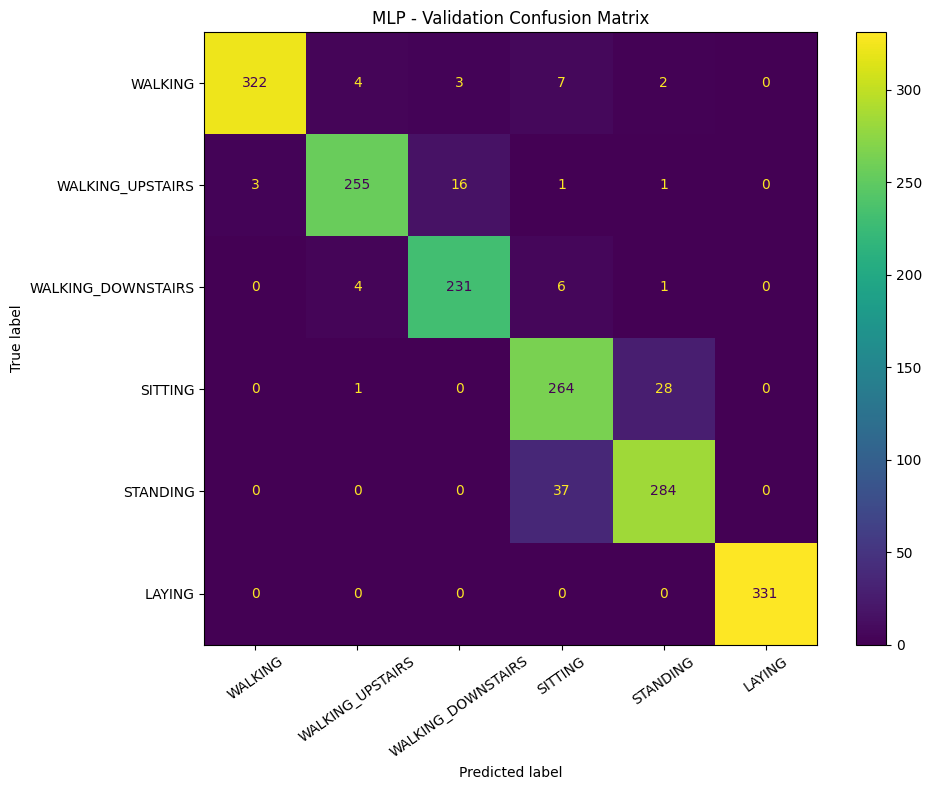

In [116]:
cm = confusion_matrix(y_mlp_val, predictions, labels=range(6))
display_cm = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=act_names)
fig, ax = plt.subplots(figsize=(10, 8))
display_cm.plot(ax=ax, xticks_rotation=35)
plt.title(f'{best_arch} - Validation Confusion Matrix')
plt.tight_layout()
plt.savefig('figures/step18_validation_confusion_matrix.png', dpi=300)
plt.show()

In [117]:
report = classification_report(y_mlp_val,predictions,labels=range(6),target_names=act_names,output_dict=True,zero_division=0)
pd.DataFrame(report).T.to_csv('results/step18_validation_class_report.csv')
print('Confusion matrix and report saved!')


Confusion matrix and report saved!


### 11.4 Representative Errors


In [118]:
subject_ids = np.loadtxt(dataset_path / 'train/subject_train.txt', dtype=int)
error_df = pd.DataFrame({"original_training_row": val_idx,"subject": subject_ids[val_idx],"actual_id": y_mlp_val,"predicted_id": predictions,"confidence": probabilities.max(axis=1)})
errors = error_df[error_df['actual_id'] != error_df['predicted_id']].copy()
errors['actual_activity'] = errors['actual_id'].map(dict(enumerate(act_names)))
errors['predicted_activity'] = errors['predicted_id'].map(dict(enumerate(act_names)))
errors.to_csv('results/step18_all_validation_errors.csv', index=False)
five_errors = errors.sample(n=min(5, len(errors)), random_state=42) if len(errors) else errors.copy()

In [119]:
display(five_errors[['subject', 'actual_activity', 'predicted_activity', 'confidence']])
five_errors.to_csv('results/step18_five_errors.csv', index=False)
print('Total validation errors:', len(errors))
print('Examples selected:', len(five_errors))

,subject,actual_activity,predicted_activity,confidence
1184,25,WALKING_DOWNSTAIRS,SITTING,0.694936
450,3,WALKING,WALKING_UPSTAIRS,0.457813
1026,25,STANDING,SITTING,0.816132
1150,25,WALKING,SITTING,0.884548
570,3,SITTING,STANDING,0.635654


Total validation errors: 114
Examples selected: 5


### 11.5 Robustness to Input Noise


In [120]:
noise_rng = np.random.default_rng(888)
NOISE_LEVEL = 0.1
noise = noise_rng.normal(loc=0.0, scale=NOISE_LEVEL, size=X_diagnostic.shape).astype(np.float32)
X_noisy = X_diagnostic + noise
noisy_probabilities = chosen_model.predict(X_noisy, verbose=0)
noisy_predictions = np.argmax(noisy_probabilities, axis=1)

In [121]:
robustness_df = pd.DataFrame({"Condition": ["Clean Validation","Gaussian Noise 0.10" ],
    "Samples": [len(y_mlp_val),len(y_mlp_val)],
    "Accuracy": [ accuracy_score(y_mlp_val, predictions),accuracy_score(y_mlp_val, noisy_predictions)],
    "Macro F1": [f1_score(y_mlp_val, predictions, average="macro", zero_division=0 ),f1_score(y_mlp_val, noisy_predictions, average="macro", zero_division=0)]})

display(robustness_df.round(4))
robustness_df.to_csv('results/step18_robustness.csv', index=False)
print('Robustness analysis completed')

,Condition,Samples,Accuracy,Macro F1
0,Clean Validation,1801,0.9367,0.9358
1,Gaussian Noise 0.10,1801,0.9373,0.9364


Robustness analysis completed


## 12. Final Model Selection and Official Test Evaluation

### 12.1 Freeze Configurations and Prepare Test Inputs

Architecture selection used mean validation macro F1. All frozen main checkpoints then saw the same official test partition. Seed 42 was the reference for diagnostics and inference.


In [122]:
main_df = pd.read_csv('results/step18_repeated_runs.csv')
abl_df = pd.read_csv('results/step18_ablation_runs.csv')
SEEDS = [42, 123, 2026]
for architecture in ["MLP", "RNN"]:
    recorded = main_df.loc[main_df["architecture"] == architecture,"seed"].tolist()
    assert sorted(recorded) == sorted(SEEDS)

assert sorted(abl_df['seed'].tolist()) == sorted(SEEDS)
assert abl_df['architecture'].nunique() == 1
ablated_architecture = abl_df['architecture'].iloc[0]


In [123]:
final_cfg = {}
for architecture in ["MLP", "RNN"]:

    original = main_df[main_df["architecture"] == architecture]

    chosen_tag = "main"
    chosen_dropout = 0.25
    chosen_scores = original

    if architecture == ablated_architecture:

        if (
            abl_df["macro_f1"].mean()
            > original["macro_f1"].mean()
        ):
            chosen_tag = "no_dropout"
            chosen_dropout = 0.0
            chosen_scores = abl_df

    checkpoints = {}

    for seed in SEEDS:
        path = (
            f"models/step18_{architecture.lower()}_"
            f"{chosen_tag}_seed{seed}.keras")
        assert Path(path).exists(), f"Missing: {path}"
        checkpoints[str(seed)] = path

    final_cfg[architecture] = {
        "tag": chosen_tag,"dropout": chosen_dropout,
        "validation_macro_f1_mean": float(chosen_scores["macro_f1"].mean()),
        "validation_macro_f1_std": float(chosen_scores["macro_f1"].std()),
        "checkpoints": checkpoints}


In [124]:
val_winner = max(final_cfg, key=lambda a: final_cfg[a]['validation_macro_f1_mean'])
frozen_cfg = {
    "dataset": "UCI HAR","seeds": SEEDS,"primary_metric": "macro_f1",
    "selection_basis": "validation data only","validation_leader": val_winner, "architectures": final_cfg}

with open("results/frozen_final_configurations.json","w",encoding="utf-8") as f:
    json.dump(frozen_cfg, f, indent=4)


In [125]:
print('Final configurations frozen successfully!')
print('Validation leader:', val_winner)
display(pd.DataFrame([
    {   "Model": name,
        "Dropout": config["dropout"],
        "Mean Validation F1": config["validation_macro_f1_mean"],
        "Std Validation F1": config["validation_macro_f1_std"]}
    for name, config in final_cfg.items()
]))


Final configurations frozen successfully!
Validation leader: MLP


,Model,Dropout,Mean Validation F1,Std Validation F1
0,MLP,0.25,0.941508,0.004927
1,RNN,0.25,0.881332,0.032491


In [126]:
dataset_path = Path('data/UCI HAR Dataset')

def load_test_xyz(sensor_name):

    folder = dataset_path / "test/Inertial Signals"

    axes = [np.loadtxt(folder / f"{sensor_name}_{axis}_test.txt", dtype=np.float32 ) for axis in ["x", "y", "z"]]
    return np.stack(axes, axis=2)

body_acc_test = load_test_xyz('body_acc')
total_acc_test = load_test_xyz('total_acc')
gyro_test = load_test_xyz('body_gyro')
gravity_test = total_acc_test - body_acc_test
X_test_raw = np.concatenate([body_acc_test, gravity_test, gyro_test], axis=2)

In [127]:
st_scaler = joblib.load('models/sensor_scaler.joblib')
X_test_seq = st_scaler.transform(X_test_raw.reshape(-1, 9)).reshape(-1, 128, 9).astype(np.float32)
X_test_flat = X_test_seq.reshape(-1, 1152)
y_test_final = np.loadtxt(dataset_path / 'test/y_test.txt', dtype=np.int32) - 1
assert X_test_seq.shape == (2947, 128, 9)
assert X_test_flat.shape == (2947, 1152)
assert len(y_test_final) == 2947
assert np.isfinite(X_test_seq).all()

c:\Users\chali\AppData\Local\Programs\Python\Python311\Lib\site-packages\sklearn\base.py:380: InconsistentVersionWarning: Trying to unpickle estimator StandardScaler from version 1.9.1 when using version 1.6.1. This might lead to breaking code or invalid results. Use at your own risk. For more info please refer to:
https://scikit-learn.org/stable/model_persistence.html#security-maintainability-limitations
  warnings.warn(


In [128]:
split_info = np.load('data/splits/subject_split_seed42.npz')
training_subjects = np.loadtxt(dataset_path / 'train/subject_train.txt', dtype=int)
testing_subjects = np.loadtxt(dataset_path / 'test/subject_test.txt', dtype=int)
train_people = set(training_subjects[split_info['train_indices']])
validation_people = set(training_subjects[split_info['validation_indices']])
test_people = set(testing_subjects)
assert train_people.isdisjoint(validation_people)
assert train_people.isdisjoint(test_people)
assert validation_people.isdisjoint(test_people)

In [129]:
print('RNN test data:', X_test_seq.shape)
print('MLP test data:', X_test_flat.shape)
print('Test labels:', y_test_final.shape)
print('Participant leakage check: PASSED')
print('Official test data ready!')

RNN test data: (2947, 128, 9)
MLP test data: (2947, 1152)
Test labels: (2947,)
Participant leakage check: PASSED
Official test data ready!


### 12.2 Final Test Results


In [130]:
test_scores = []

lr_model = joblib.load('models/logistic_regression.joblib')

lr_pred = lr_model.predict(X_test_flat)

test_scores.append({ "Model": "Logistic Regression",
    "Seed": "baseline",
    "Test Accuracy": accuracy_score( y_test_final, lr_pred ),
    "Test Macro F1": f1_score( y_test_final, lr_pred, average="macro", zero_division=0 ),
    "Parameters": "N/A"})


c:\Users\chali\AppData\Local\Programs\Python\Python311\Lib\site-packages\sklearn\base.py:380: InconsistentVersionWarning: Trying to unpickle estimator LogisticRegression from version 1.9.1 when using version 1.6.1. This might lead to breaking code or invalid results. Use at your own risk. For more info please refer to:
https://scikit-learn.org/stable/model_persistence.html#security-maintainability-limitations
  warnings.warn(


In [131]:
for architecture in ["MLP", "RNN"]:

    config = final_cfg[architecture]

    X_input = ( X_test_flat if architecture == "MLP" else X_test_seq )

    for seed in SEEDS:

        print( f"Evaluating {architecture}, seed {seed}")

        model_path = config["checkpoints"][str(seed)]
        model = tf.keras.models.load_model(model_path)
        probabilities = model.predict( X_input, batch_size=64,verbose=0)
        predictions = np.argmax(probabilities, axis=1)

        test_scores.append({"Model": architecture,"Seed": seed,"Test Accuracy": accuracy_score( y_test_final, predictions ), "Test Macro F1": f1_score( y_test_final, predictions,  average="macro",zero_division=0 ),"Parameters": model.count_params()})

        if seed == 42:
            np.savez(f"results/step19_{architecture.lower()}" "_seed42_test_predictions.npz", actual=y_test_final, predicted=predictions, probabilities=probabilities )
        del model
        gc.collect()


Evaluating MLP, seed 42
Evaluating MLP, seed 123
Evaluating MLP, seed 2026
Evaluating RNN, seed 42
Evaluating RNN, seed 123
Evaluating RNN, seed 2026


In [132]:
test_df = pd.DataFrame(test_scores)
test_df.to_csv('results/step19_final_test_results.csv', index=False)
display(test_df)

,Model,Seed,Test Accuracy,Test Macro F1,Parameters
0,Logistic Regression,baseline,0.575161,0.546972,N/A
1,MLP,42,0.894469,0.892249,156230
2,MLP,123,0.902952,0.902023,156230
3,MLP,2026,0.895826,0.894845,156230
4,RNN,42,0.817102,0.813970,3846
5,RNN,123,0.758059,0.751335,3846
6,RNN,2026,0.807601,0.805714,3846


In [133]:
nn_test_df = test_df[test_df['Model'].isin(['MLP', 'RNN'])]
test_stats = nn_test_df.groupby("Model").agg(Mean_Test_Accuracy=("Test Accuracy", "mean"), Std_Test_Accuracy=("Test Accuracy", "std"), Mean_Test_Macro_F1=("Test Macro F1", "mean"),Std_Test_Macro_F1=("Test Macro F1", "std"),Parameters=("Parameters", "first")).reset_index()

In [134]:
display(test_stats.round(4))
test_stats.to_csv('results/step19_test_summary.csv', index=False)
print('Test summary saved')

,Model,Mean_Test_Accuracy,Std_Test_Accuracy,Mean_Test_Macro_F1,Std_Test_Macro_F1,Parameters
0,MLP,0.8977,0.0046,0.8964,0.0051,156230
1,RNN,0.7943,0.0317,0.7903,0.0340,3846


Test summary saved


### 12.3 Test Confusion Matrix and Class Metrics


In [135]:
act_names = ['WALKING', 'WALKING_UPSTAIRS', 'WALKING_DOWNSTAIRS', 'SITTING', 'STANDING', 'LAYING']
saved_pred = np.load(f'results/step19_{val_winner.lower()}_seed42_test_predictions.npz')
test_pred = saved_pred['predicted']
cm = confusion_matrix(y_test_final, test_pred, labels=range(6))

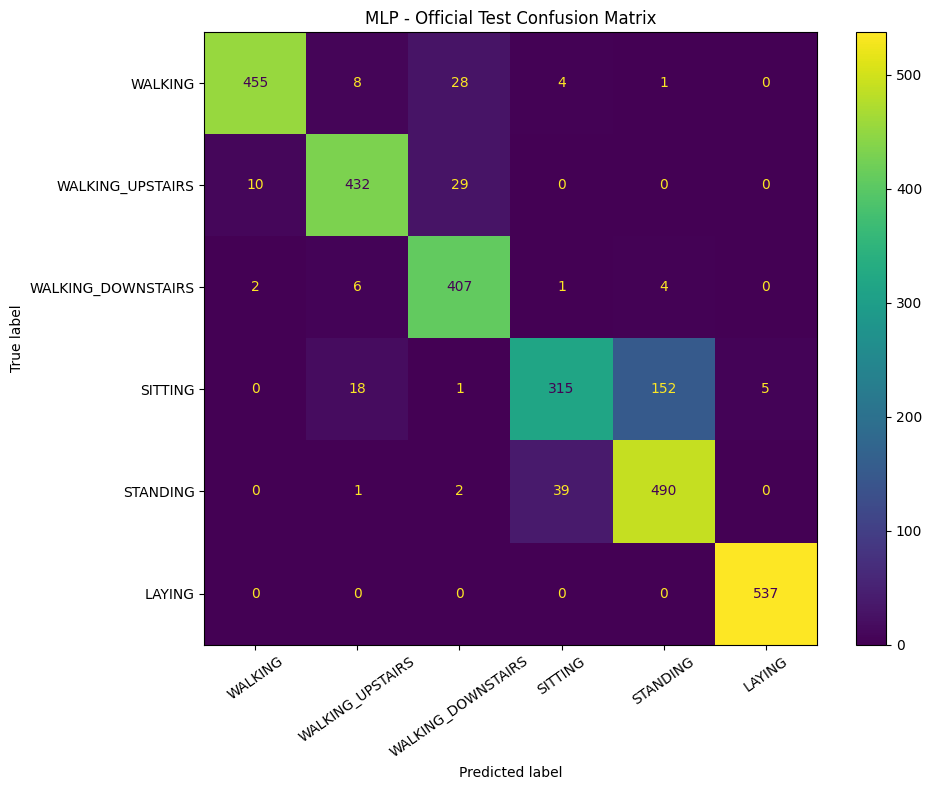

In [136]:
fig, ax = plt.subplots(figsize=(10, 8))
ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=act_names).plot(ax=ax, xticks_rotation=35)
plt.title(f'{val_winner} - Official Test Confusion Matrix')
plt.tight_layout()
plt.savefig('figures/step19_final_confusion_matrix.png', dpi=300)
plt.show()

In [137]:
print(classification_report( y_test_final,test_pred,labels=range(6),target_names=act_names,zero_division=0))
report = classification_report( y_test_final, test_pred,labels=range(6),target_names=act_names, output_dict=True,zero_division=0)
pd.DataFrame(report).T.to_csv('results/step19_final_classification_report.csv')

                    precision    recall  f1-score   support

           WALKING       0.97      0.92      0.94       496
  WALKING_UPSTAIRS       0.93      0.92      0.92       471
WALKING_DOWNSTAIRS       0.87      0.97      0.92       420
           SITTING       0.88      0.64      0.74       491
          STANDING       0.76      0.92      0.83       532
            LAYING       0.99      1.00      1.00       537

          accuracy                           0.89      2947
         macro avg       0.90      0.89      0.89      2947
      weighted avg       0.90      0.89      0.89      2947



## 13. Inference Speed Benchmark


In [138]:
BATCH = 32
SAMPLES = 256
REPETITIONS = 5
timing_results = []

def measure_inference(model, X, is_neural):

    X = X[:SAMPLES]
    def predict_all():
        for start in range(0, len(X), BATCH):
            batch = X[start:start + BATCH]

            if is_neural:
                with tf.device("/CPU:0"):
                    output = model(batch, training=False)
                    _ = output.numpy()
            else:
                _ = model.predict(batch)

    for _ in range(2):
        predict_all()

    measurements = []

    for _ in range(REPETITIONS):
        start = time.perf_counter()
        predict_all()
        measurements.append( time.perf_counter() - start)

    return np.mean(measurements) * 1000 / SAMPLES


In [139]:
timing_results.append({"Model": "Logistic Regression", "Milliseconds per sample": measure_inference(lr_model, X_test_flat, False),"Parameters": "N/A"})

for architecture in ["MLP", "RNN"]:
    model = tf.keras.models.load_model( final_cfg[architecture]["checkpoints"]["42"])
    X_input = ( X_test_flat if architecture == "MLP" else X_test_seq)
    timing_results.append({ "Model": architecture,"Milliseconds per sample": measure_inference( model, X_input, True), "Parameters": model.count_params()})


In [140]:
timing_df = pd.DataFrame(timing_results)
timing_df['Batch Size'] = BATCH
timing_df['Hardware'] = platform.processor()
timing_df['Device'] = 'CPU'
display(timing_df)
timing_df.to_csv('results/step19_inference_timing.csv', index=False)

,Model,Milliseconds per sample,Parameters,Batch Size,Hardware,Device
0,Logistic Regression,0.018137,N/A,32,"Intel64 Family 6 Model 154 Stepping 3, Genuine...",CPU
1,MLP,0.557918,156230,32,"Intel64 Family 6 Model 154 Stepping 3, Genuine...",CPU
2,RNN,21.410381,3846,32,"Intel64 Family 6 Model 154 Stepping 3, Genuine...",CPU


## 14. Demonstration Inputs


In [141]:
Path('data/demo').mkdir(parents=True, exist_ok=True)
valid_sample = X_test_raw[0].astype(np.float32)
np.save('data/demo/test_sample_000.npy', valid_sample)

In [142]:
invalid_sample = np.zeros((10, 9), dtype=np.float32)
np.save('data/demo/invalid_sample.npy', invalid_sample)

In [143]:
print('Valid sample shape:', valid_sample.shape)
print('Invalid sample shape:', invalid_sample.shape)
print('Actual activity ID:', int(y_test_final[0]) + 1)
print('Demo files saved successfully!')

Valid sample shape: (128, 9)
Invalid sample shape: (10, 9)
Actual activity ID: 5
Demo files saved successfully!


## 15. Reproducibility and Submission Export


In [ ]:
import subprocess
with open("requirements.txt","w",encoding="utf-8") as file:

    subprocess.run([
            sys.executable,
            "-m",
            "pip",
            "freeze"],
        stdout=file,
        check=True)

In [ ]:
from zipfile import ZIP_DEFLATED
zip_path = Path('ANN_CW1_Submission.zip')
individual_files = ["main.ipynb","predict_har.py","smoke_test.py","README.md","requirements.txt"]
included_folders = ['models', 'results', 'figures', 'data/splits', 'data/demo']


In [ ]:
with ZipFile(zip_path,"w",compression=ZIP_DEFLATED) as archive:

    for filename in individual_files:
        path = Path(filename)

        if not path.exists():
            raise FileNotFoundError(f"Missing required file: {filename}")

        archive.write(path, arcname=str(path))

    for folder in included_folders:
        directory = Path(folder)

        if not directory.exists():
            raise FileNotFoundError(f"Missing folder: {folder}")

        for file in directory.rglob("*"):
            if file.is_file():
                archive.write(file, arcname=str(file))

In [ ]:
print('CW1 ZIP created:', zip_path)
print('ZIP size (MB):', round(zip_path.stat().st_size / 1024 ** 2, 2))

CW1 ZIP created: ANN_CW1_Submission.zip
ZIP size (MB): 14.16


In [ ]:
with ZipFile(zip_path) as archive:
    bad_file = archive.testzip()
    assert bad_file is None
print('ZIP integrity check PASSED!')


ZIP integrity check PASSED!
